# Fase 2 – Data Understanding

Esta fase tem como objetivo conhecer os dados tal como foram fornecidos: a sua origem, estrutura, significado e qualidade. Segue as quatro tarefas da metodologia CRISP-DM, aplicando em cada uma os passos correspondentes do processo EDA:

| Tarefa CRISP-DM | Passos EDA |
|---|---|
| 2.1 Recolha inicial dos dados | Passos 1 e 2 – Compreender e inspecionar |
| 2.2 Descrição dos dados | Passos 4 e 6 – Explorar e visualizar |
| 2.3 Exploração dos dados | Passos 5 e 8 – Transformar e reportar |
| 2.4 Verificação da qualidade | Passos 3 e 7 – Ausentes e outliers |

**Princípio desta fase:** os dados são analisados tal como foram fornecidos. Nenhum valor é corrigido, removido ou criado; os problemas encontrados são identificados e documentados, e o seu tratamento é feito na Fase 3 – Data Preparation.

## 2.1 Recolha Inicial dos Dados (Collect Initial Data)
> **CRISP-DM:** obter os dados listados nos recursos do projeto e carregá-los na ferramenta de análise. Output: *Initial Data Collection Report*, com os datasets obtidos, a sua localização, o método de obtenção e os problemas encontrados, bem como a forma como foram resolvidos.
>
> **Passos EDA:** 1 – Compreensão do problema e dos dados; 2 – Importação e inspeção inicial.

**Contexto (Business Understanding):** os dados provêm de uma Unidade de Cuidados Intensivos Neonatais e foram disponibilizados na competição Kaggle da unidade curricular, em duas tabelas: sinais vitais por hora e patologias por dia, ligadas pelo código de episódio. Cada episódio é um acontecimento clínico e não identifica o bebé.

In [2]:
# =============================================================================
# 2.1.1 Bibliotecas, estilo dos gráficos e localização dos dados
# pandas: tabelas | numpy: cálculos | matplotlib/seaborn: gráficos
# os: verificar os ficheiros na pasta de dados
# Define também um estilo e uma paleta de cores comuns a todos os gráficos:
#   AZUL = valores normais | AZUL_CLARO = áreas e caixas | VERMELHO = problemas
#   e referências | LARANJA = ausências | CINZA = texto secundário
# Os ficheiros foram descarregados da competição Kaggle da unidade curricular
# e guardados na pasta "dados/" do repositório.
# =============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Paleta de cores usada em todos os gráficos
AZUL, AZUL_CLARO, VERMELHO, LARANJA, CINZA = "#2F5496", "#DCE6F2", "#C00000", "#F4B183", "#555555"

# Estilo comum dos gráficos
sns.set_theme(style="whitegrid", rc={
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#EEEEEE", "figure.dpi": 100,
})

PASTA_DADOS = "dados/"           # usar "../dados/" se o notebook estiver na pasta notebooks/
FICH_SINAIS = "sinais_vitais_por_hora.csv"
FICH_PATOLOGIAS = "patologias_por_dia.csv"


In [3]:
# =============================================================================
# 2.1.2 Ficheiros obtidos
# Lista todos os ficheiros da pasta de dados e o respetivo tamanho, para
# documentar exatamente o que foi obtido.
# =============================================================================
for f in sorted(os.listdir(PASTA_DADOS)):
    tamanho_kb = os.path.getsize(os.path.join(PASTA_DADOS, f)) / 1024
    print(f"{f:40s} {tamanho_kb:8.1f} KB")

patologias_por_dia.csv                       28.1 KB
sinais_vitais_por_hora.csv                  367.2 KB


In [4]:
# =============================================================================
# 2.1.3 Inspeção do ficheiro em bruto
# Antes de usar o pandas, lê cada ficheiro como texto: conta as linhas e
# mostra as primeiras. Permite confirmar o separador (vírgula ou ponto e
# vírgula), o separador decimal, a existência de cabeçalho e a codificação
# dos acentos, tal como estão no ficheiro original.
# =============================================================================
for fich in [FICH_SINAIS, FICH_PATOLOGIAS]:
    caminho = os.path.join(PASTA_DADOS, fich)
    with open(caminho, encoding="utf-8", errors="replace") as f:
        linhas = f.readlines()
    print(f"--- {fich}: {len(linhas)} linhas no ficheiro (incluindo o cabeçalho) ---")
    for linha in linhas[:5]:
        print(linha.rstrip())
    print()

--- sinais_vitais_por_hora.csv: 9858 linhas no ficheiro (incluindo o cabeçalho) ---
episodio,data,hora,sat_o2,puls_rate,perfusion
EP001,2024-01-30,9,93.5,158.63,0.99
EP001,2024-01-30,10,92.3,155.86,0.86
EP002,2024-01-30,10,94.31,133.2,0.91
EP001,2024-01-30,11,93.96,150.0,1.13

--- patologias_por_dia.csv: 697 linhas no ficheiro (incluindo o cabeçalho) ---
episodio,data,patologia
EP001,2024-01-30,Displasia broncopulmonar
EP001,2024-01-30,Refluxo gastroesofágico
EP003,2024-01-30,Doença das membranas hialinas
EP003,2024-01-30,Doença das membranas hialinas



In [5]:
# =============================================================================
# 2.1.4 Carregamento dos dados
# Carrega cada ficheiro para uma tabela (DataFrame). Tenta a codificação
# UTF-8; se falhar, usa latin-1. A codificação usada fica registada para o
# relatório de recolha.
# df_sinais -> sinais vitais por hora | df_patologias -> patologias por dia
# =============================================================================
def carregar_csv(nome):
    caminho = os.path.join(PASTA_DADOS, nome)
    try:
        df = pd.read_csv(caminho, encoding="utf-8")
        cod = "utf-8"
    except UnicodeDecodeError:
        df = pd.read_csv(caminho, encoding="latin-1")
        cod = "latin-1"
    print(f"{nome}: carregado com codificação {cod}")
    return df

df_sinais = carregar_csv(FICH_SINAIS)
df_patologias = carregar_csv(FICH_PATOLOGIAS)

sinais_vitais_por_hora.csv: carregado com codificação utf-8
patologias_por_dia.csv: carregado com codificação utf-8


In [6]:
# =============================================================================
# 2.1.5 Volumetria
# Nº de registos e campos de cada tabela, comparado com o nº de linhas de
# dados no ficheiro em bruto (sem cabeçalho nem linhas vazias). Se os
# números não coincidirem, houve linhas que o pandas não leu como esperado.
# =============================================================================
for nome, fich, df in [("Sinais vitais", FICH_SINAIS, df_sinais),
                       ("Patologias", FICH_PATOLOGIAS, df_patologias)]:
    with open(os.path.join(PASTA_DADOS, fich), encoding="utf-8", errors="replace") as f:
        linhas_ficheiro = sum(1 for linha in f if linha.strip()) - 1
    print(f"{nome}: {df.shape[0]} registos x {df.shape[1]} campos "
          f"| linhas de dados no ficheiro: {linhas_ficheiro}")

Sinais vitais: 9857 registos x 6 campos | linhas de dados no ficheiro: 9857
Patologias: 696 registos x 3 campos | linhas de dados no ficheiro: 696


In [7]:
# =============================================================================
# 2.1.6 Campos obtidos vs. dicionário de dados
# Compara os nomes das colunas com os do dicionário de dados fornecido pelo
# docente. Deteta colunas em falta, colunas a mais e diferenças de escrita
# (ex.: espaços escondidos ou maiúsculas).
# =============================================================================
dicionario = {
    "Sinais vitais": ["episodio", "data", "hora", "sat_o2", "puls_rate", "perfusion"],
    "Patologias": ["episodio", "data", "patologia"],
}
for nome, df in [("Sinais vitais", df_sinais), ("Patologias", df_patologias)]:
    obtidas = df.columns.tolist()
    print(f"{nome}: {obtidas}")
    print("   Em falta face ao dicionário:", set(dicionario[nome]) - set(obtidas) or "nenhuma")
    print("   A mais face ao dicionário:  ", set(obtidas) - set(dicionario[nome]) or "nenhuma")

Sinais vitais: ['episodio', 'data', 'hora', 'sat_o2', 'puls_rate', 'perfusion']
   Em falta face ao dicionário: nenhuma
   A mais face ao dicionário:   nenhuma
Patologias: ['episodio', 'data', 'patologia']
   Em falta face ao dicionário: nenhuma
   A mais face ao dicionário:   nenhuma


In [8]:
# =============================================================================
# 2.1.7 Tipos atribuídos e valores não nulos
# info() mostra, para cada coluna, o tipo que o pandas atribuiu ao ler o
# ficheiro e o nº de valores não nulos.
# Tipos esperados pelo dicionário de dados:
#   hora -> número inteiro | sat_o2, puls_rate, perfusion -> número decimal
#   episodio, data, patologia -> texto
# Uma coluna que deveria ser numérica mas é lida como texto contém pelo menos
# um valor não numérico (a analisar nas tarefas seguintes).
# =============================================================================
print("===== SINAIS VITAIS =====")
df_sinais.info()
print("\n===== PATOLOGIAS =====")
df_patologias.info()

===== SINAIS VITAIS =====
<class 'pandas.DataFrame'>
RangeIndex: 9857 entries, 0 to 9856
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   9857 non-null   str  
 1   data       9857 non-null   str  
 2   hora       9857 non-null   int64
 3   sat_o2     9813 non-null   str  
 4   puls_rate  9793 non-null   str  
 5   perfusion  9815 non-null   str  
dtypes: int64(1), str(5)
memory usage: 462.2 KB

===== PATOLOGIAS =====
<class 'pandas.DataFrame'>
RangeIndex: 696 entries, 0 to 695
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   696 non-null    str  
 1   data       696 non-null    str  
 2   patologia  684 non-null    str  
dtypes: str(3)
memory usage: 16.4 KB


In [9]:
# =============================================================================
# 2.1.8 Amostras dos dados
# head(): primeiras linhas de cada tabela.
# sample(): linhas aleatórias de todo o ficheiro, onde é mais provável
# encontrar valores invulgares. random_state fixa a amostra (reprodutível).
# =============================================================================
display(df_sinais.head())
display(df_sinais.sample(10, random_state=42))
display(df_patologias.head())
display(df_patologias.sample(10, random_state=42))

,episodio,data,hora,sat_o2,puls_rate,perfusion
0,EP001,2024-01-30,9,93.5,158.63,0.99
1,EP001,2024-01-30,10,92.3,155.86,0.86
2,EP002,2024-01-30,10,94.31,133.2,0.91
3,EP001,2024-01-30,11,93.96,150.0,1.13
4,EP002,2024-01-30,11,91.19,139.79,1.55


,episodio,data,hora,sat_o2,puls_rate,perfusion
8376,EP026,2024-04-14,5,95.24,156.27,1.19
500,EP001,2024-02-04,19,92.82,162.51,1.1
8919,EP034,2024-04-16,18,98.0,145.38,1.46
872,EP001,2024-02-08,22,91.13,154.28,1.12
5414,EP022,2024-03-17,7,94.4,149.55,2.29
5558,EP025,2024-03-18,2,97.49,126.09,1.17
7185,EP026,2024-04-03,20,94.44,146.92,0.63
7048,EP026,2024-04-01,1,96.09,157.7,1.23
1078,EP006,2024-02-11,0,97.26,143.5,1.2
8561,EP035,2024-04-15,1,94.84,142.91,2.21


,episodio,data,patologia
0,EP001,2024-01-30,Displasia broncopulmonar
1,EP001,2024-01-30,Refluxo gastroesofágico
2,EP003,2024-01-30,Doença das membranas hialinas
3,EP003,2024-01-30,Doença das membranas hialinas
4,EP003,2024-01-30,Icterícia neonatal


,episodio,data,patologia
674,EP026,2024-04-19,Displasia broncopulmonar
314,EP016,2024-03-05,Doença das membranas hialinas
611,EP039,2024-04-13,Doença das membranas hialinas
431,EP027,2024-03-17,Citomegalovírus
552,EP027,2024-04-03,Citomegalovírus
211,EP015,2024-02-24,Doença das membranas hialinas
538,EP032,2024-03-30,Sépsis
176,EP001,2024-02-20,Displasia broncopulmonar
299,EP019,2024-03-03,Icterícia neonatal
220,EP001,2024-02-26,NaN


In [10]:
# =============================================================================
# 2.1.9 Ligação entre as duas tabelas
# As tabelas ligam-se pelo código de episódio. Compara os códigos presentes
# em cada uma, tal como estão escritos nos ficheiros.
# Códigos só numa das tabelas podem ser episódios sem registos na outra, ou
# o mesmo episódio escrito de forma diferente (a analisar nas tarefas seguintes).
# =============================================================================
ep_sinais = set(df_sinais["episodio"].dropna())
ep_patologias = set(df_patologias["episodio"].dropna())

print("Códigos de episódio nos sinais vitais:", len(ep_sinais))
print("Códigos de episódio nas patologias:   ", len(ep_patologias))
print("Presentes em ambas as tabelas:        ", len(ep_sinais & ep_patologias))
print("\nSó nos sinais vitais:", sorted(ep_sinais - ep_patologias))
print("Só nas patologias:   ", sorted(ep_patologias - ep_sinais))

Códigos de episódio nos sinais vitais: 58
Códigos de episódio nas patologias:    45
Presentes em ambas as tabelas:         40

Só nos sinais vitais: [' EP011', ' EP016', ' EP027', 'EP 016', 'EP 026', 'EP 034', 'EP 036', 'EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047', 'ep016', 'ep019', 'ep023']
Só nas patologias:    [' EP009', ' EP020', 'EP 018', 'EP 037', 'ep029']


### Relatório de Recolha Inicial dos Dados

**Datasets obtidos**

| Dataset | Localização | Método de obtenção | Registos × campos | Formato |
|---|---|---|---|---|
| sinais_vitais_por_hora.csv (367,2 KB) | dados/ | Download da competição Kaggle da unidade curricular | 9 857 × 6 | CSV, separador vírgula, ponto decimal, com cabeçalho, UTF-8 |
| patologias_por_dia.csv (28,1 KB) | dados/ | Download da competição Kaggle da unidade curricular | 696 × 3 | CSV, separador vírgula, ponto decimal, com cabeçalho, UTF-8 |

Os dois ficheiros foram carregados em Python (pandas) sem erros de leitura. O número de registos carregados coincide com o número de linhas de dados de cada ficheiro, e todos os campos do dicionário de dados estão presentes, sem colunas adicionais. Não existem outras fontes de dados para o projeto.

**Problemas encontrados**

| Problema | Onde | Observação | Tratamento |
|---|---|---|---|
| Colunas numéricas lidas como texto | sat_o2, puls_rate, perfusion | Existem valores não numéricos nestas colunas | Identificar e quantificar na tarefa 2.4 |
| Valores em falta | sat_o2 (44), puls_rate (64), perfusion (42), patologia (12) | Representados como células vazias | Caracterizar na tarefa 2.4 |
| Registos repetidos | Patologias | Ex.: EP003, 30/01/2024, doença das membranas hialinas, em duas linhas | Quantificar na tarefa 2.4 |
| Códigos de episódio escritos de formas diferentes | Ambas as tabelas | Códigos com espaço no início (" EP011"), espaço no meio ("EP 016") e minúsculas ("ep016") | Quantificar o número real de episódios na tarefa 2.4 |

**Ligação entre as tabelas**

As duas tabelas ligam-se pelo campo `episodio`. Tal como estão escritos, existem 58 códigos nos sinais vitais e 45 nas patologias, com 40 em comum. Parte da diferença resulta de o mesmo código aparecer escrito de formas diferentes. As tabelas têm também granularidades diferentes: os sinais vitais são registados por hora e as patologias por dia. A integração das duas fontes será feita na Fase 3.

## 2.2 Descrição dos Dados (Describe Data)
> **CRISP-DM:** examinar as propriedades "de superfície" dos dados obtidos: formato, quantidade (registos e campos de cada tabela), identidade dos campos e outras características gerais. Avaliar se os dados satisfazem os requisitos do projeto. Output: *Data Description Report*.
>
> **Passos EDA:** 4 – Medidas de tendência central e dispersão; 6 – Visualização.

Para cada variável compara-se o que é esperado (dicionário de dados fornecido) com o que é observado nos dados, tal como foram recebidos.

### 2.2.1 Dicionário de dados

**Tabela `sinais_vitais_por_hora`** – uma linha por episódio, por dia e por hora.

| Campo | Descrição | Tipo de variável | Unidade | Domínio esperado |
|---|---|---|---|---|
| episodio | Código do episódio clínico (comum às duas tabelas) | Qualitativa nominal (identificador) | – | Códigos no formato EPnnn |
| data | Dia do registo | Temporal | – | Datas válidas no formato AAAA-MM-DD |
| hora | Hora do dia (9 = 09:00 a 09:59) | Quantitativa discreta | h | Inteiros de 0 a 23 |
| sat_o2 | Saturação periférica de oxigénio (SpO2), medida pelo oxímetro de pulso; valor típico da hora | Quantitativa contínua | % | 0 a 100 |
| puls_rate | Frequência de pulso, medida pelo oxímetro de pulso; valor típico da hora | Quantitativa contínua | bpm | Valores positivos |
| perfusion | Índice de perfusão: força do pulso na zona do sensor; valor típico da hora | Quantitativa contínua | % | Valores positivos |

**Tabela `patologias_por_dia`** – uma linha por patologia confirmada no registo clínico de um episódio num dia.

| Campo | Descrição | Tipo de variável | Unidade | Domínio esperado |
|---|---|---|---|---|
| episodio | Código do episódio clínico (comum às duas tabelas) | Qualitativa nominal (identificador) | – | Códigos no formato EPnnn |
| data | Dia do registo | Temporal | – | Datas válidas no formato AAAA-MM-DD |
| patologia | Patologia confirmada | Qualitativa nominal | – | 13 valores: Sépsis; Hemorragia peri-intraventricular; Lesão renal aguda; Persistência do canal arterial; Anemia; Enterocolite necrosante; Displasia broncopulmonar; Retinopatia da prematuridade; Icterícia neonatal; Doença das membranas hialinas; Doença metabólica óssea da prematuridade; Citomegalovírus; Refluxo gastroesofágico |

**Notas:**
- O episódio é um acontecimento clínico e não identifica o bebé: o mesmo bebé pode ter vários episódios.
- Os sinais vitais são valores já resumidos por hora ("valor típico da hora"), não medições individuais do oxímetro.
- A hora é cíclica: a hora 23 é seguida da hora 0 do dia seguinte.

In [11]:
# =============================================================================
# 2.2.2 Perfil de cada variável
# Para cada campo de cada tabela, mostra:
# - tipo atribuído pelo pandas ao ler o ficheiro
# - nº de valores não nulos, em falta e respetiva percentagem
# - nº de valores distintos
# - os 3 valores mais frequentes (e quantas vezes aparecem)
# Os dados não são alterados: é um resumo dos dados tal como foram recebidos.
# =============================================================================
def perfil(df):
    linhas = []
    for col in df.columns:
        s = df[col]
        top = s.value_counts().head(3)
        linhas.append({
            "campo": col,
            "tipo atribuído": str(s.dtype),
            "não nulos": s.notna().sum(),
            "em falta": s.isna().sum(),
            "% em falta": round(s.isna().mean() * 100, 2),
            "valores distintos": s.nunique(),
            "mais frequentes (contagem)": "; ".join(f"{v} ({n})" for v, n in top.items()),
        })
    return pd.DataFrame(linhas).set_index("campo")

print("===== SINAIS VITAIS =====")
display(perfil(df_sinais))
print("\n===== PATOLOGIAS =====")
display(perfil(df_patologias))

===== SINAIS VITAIS =====


,tipo atribuído,não nulos,em falta,% em falta,valores distintos,mais frequentes (contagem)
campo,,,,,,
episodio,str,9857,0,0.00,58,EP026 (852); EP020 (571); EP001 (562)
data,str,9857,0,0.00,97,2024-04-20 (239); 2024-04-14 (219); 2024-04-19 (219)
hora,int64,9857,0,0.00,27,11 (420); 10 (417); 8 (417)
sat_o2,str,9813,44,0.45,1044,96.98 (45); 95.98 (42); 97.0 (40)
puls_rate,str,9793,64,0.65,4399,157.96 (12); 159.96 (11); 154.94 (11)
perfusion,str,9815,42,0.43,315,1.06 (128); 0.99 (122); 1.01 (121)



===== PATOLOGIAS =====


,tipo atribuído,não nulos,em falta,% em falta,valores distintos,mais frequentes (contagem)
campo,,,,,,
episodio,str,696,0,0.00,45,EP001 (72); EP004 (51); EP015 (43)
data,str,696,0,0.00,91,2024-04-18 (14); 2024-02-07 (13); 2024-02-29 (13)
patologia,str,684,12,1.72,25,Doença das membranas hialinas (264); Icterícia neonatal (159); Anemia (52)



===== Sinais vitais =====
Códigos distintos: 58 | dentro do formato EPnnn: 47 | fora do formato: 11 (12 registos)


,registos
'ep018',2
' EP011',1
'EP 016',1
'ep019',1
'ep016',1
' EP016',1
'ep023',1
' EP027',1
'EP 034',1
'EP 036',1


Nº de registos por código (todos os códigos, tal como estão escritos):


,count,mean,std,min,25%,50%,75%,max
registos por código,58.0,169.9,196.1,1.0,22.8,80.0,223.8,852.0



===== Patologias =====
Códigos distintos: 45 | dentro do formato EPnnn: 39 | fora do formato: 6 (6 registos)


,registos
' EP009',1
'EP 018',1
'ep018',1
'ep029',1
' EP020',1
'EP 037',1


Nº de registos por código (todos os códigos, tal como estão escritos):


,count,mean,std,min,25%,50%,75%,max
registos por código,45.0,15.5,16.8,1.0,3.0,9.0,20.0,72.0


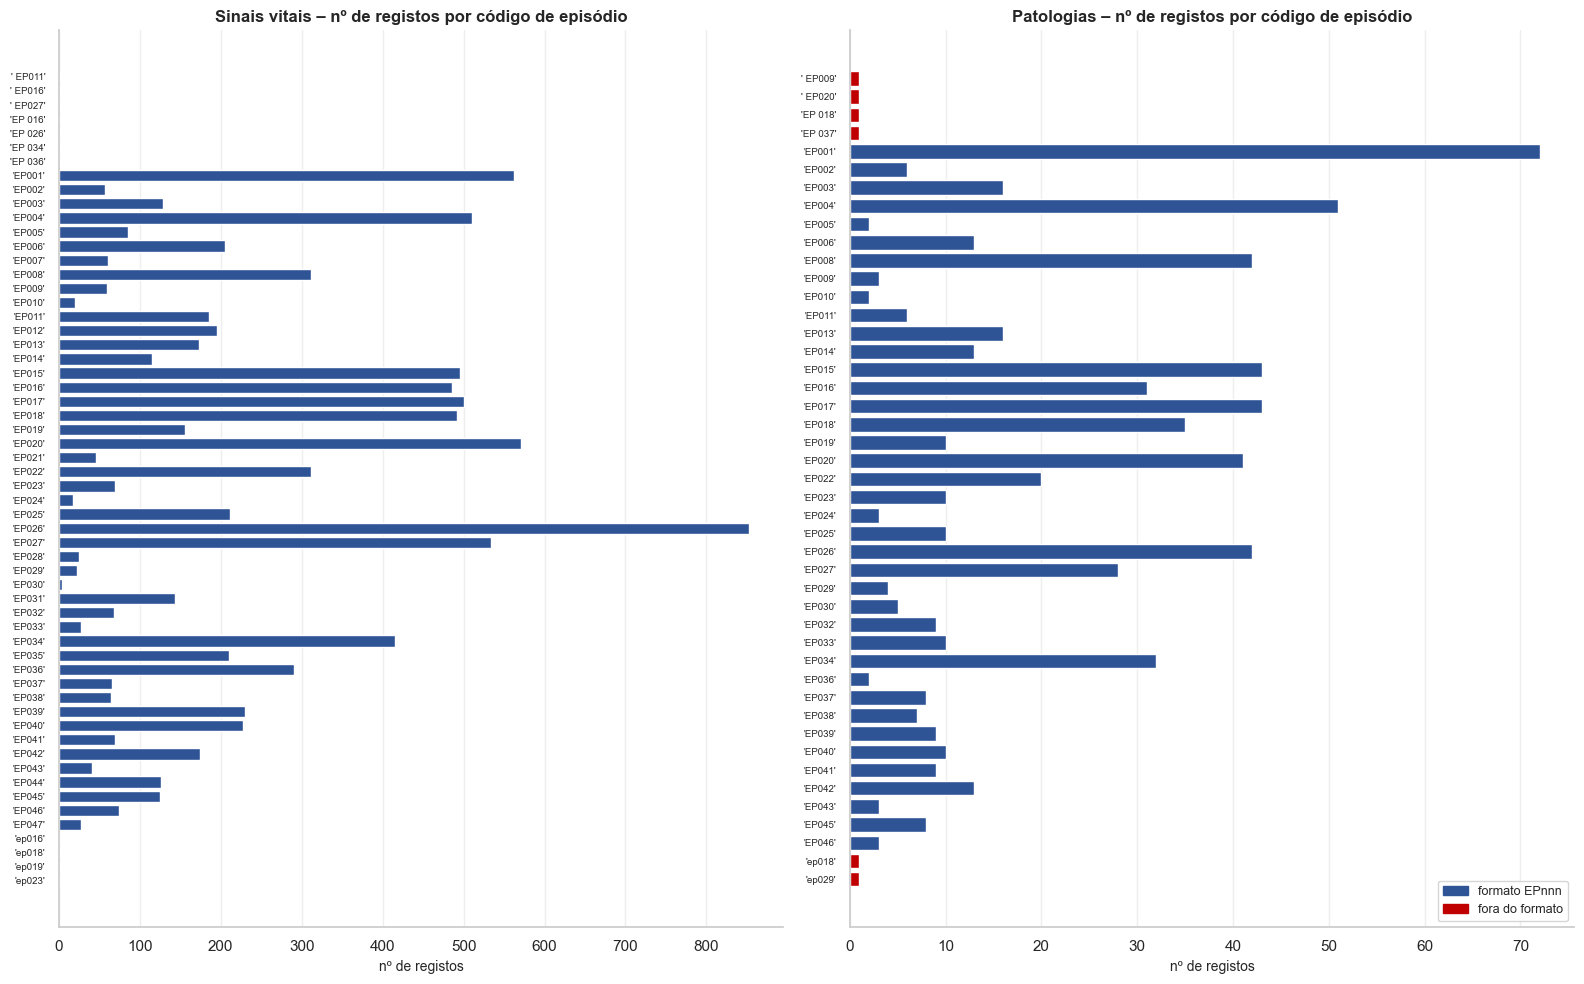

In [12]:
# =============================================================================
# 2.2.3 Variável episodio
# Verifica se os códigos seguem o formato esperado (EP + 3 algarismos) e
# lista os que não seguem, com o nº de registos de cada um. Os códigos são
# mostrados entre aspas para tornar visíveis os espaços.
# Mostra também a distribuição do nº de registos por código e um gráfico
# de barras por código (Passo 6): azul = formato EPnnn, vermelho = fora do formato.
# Os dados não são alterados.
# =============================================================================
for nome, df in [("Sinais vitais", df_sinais), ("Patologias", df_patologias)]:
    cod = df["episodio"]
    no_formato = cod.str.fullmatch(r"EP\d{3}")
    print(f"\n===== {nome} =====")
    print(f"Códigos distintos: {cod.nunique()} | dentro do formato EPnnn: {cod[no_formato].nunique()} "
          f"| fora do formato: {cod[~no_formato].nunique()} ({(~no_formato).sum()} registos)")

    fora = cod[~no_formato].value_counts()
    fora.index = [repr(c) for c in fora.index]
    display(fora.to_frame("registos"))

    print("Nº de registos por código (todos os códigos, tal como estão escritos):")
    display(cod.value_counts().describe().round(1).to_frame("registos por código").T)

# --- Visualização (Passo 6): nº de registos por código de episódio, nas duas tabelas
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for k, (nome, df) in enumerate([("Sinais vitais", df_sinais), ("Patologias", df_patologias)]):
    contagem = df["episodio"].value_counts().sort_index()
    cores_barras = [AZUL if ok else VERMELHO for ok in contagem.index.str.fullmatch(r"EP\d{3}")]
    axes[k].barh([repr(c) for c in contagem.index], contagem.values, color=cores_barras)
    axes[k].invert_yaxis()
    axes[k].tick_params(axis="y", labelsize=7)
    axes[k].grid(axis="y", visible=False)
    axes[k].set_title(f"{nome} – nº de registos por código de episódio")
    axes[k].set_xlabel("nº de registos")
axes[1].legend(handles=[Patch(color=AZUL, label="formato EPnnn"), Patch(color=VERMELHO, label="fora do formato")],
               loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()



===== Sinais vitais =====
Datas válidas: 9839 registos | inválidas: 18 registos
Período das datas válidas: 2024-01-30 a 2024-04-20 (82 dias de calendário)
Dias distintos com registos (datas válidas): 82
Valores inválidos (tal como estão escritos):


,registos
data,
10/02/2024,2
2024-13-02,2
18/04/2024,2
31/01/2024,1
05/02/2024,1
14/02/2024,1
2024-02-31,1
09/03/2024,1
13/03/2024,1



===== Patologias =====
Datas válidas: 686 registos | inválidas: 10 registos
Período das datas válidas: 2024-01-30 a 2024-04-20 (82 dias de calendário)
Dias distintos com registos (datas válidas): 82
Valores inválidos (tal como estão escritos):


,registos
data,
26/02/2024,2
10/02/2024,1
09/03/2024,1
12/03/2024,1
2024-13-02,1
20/03/2024,1
2024-02-30,1
14/04/2024,1
20/04/2024,1


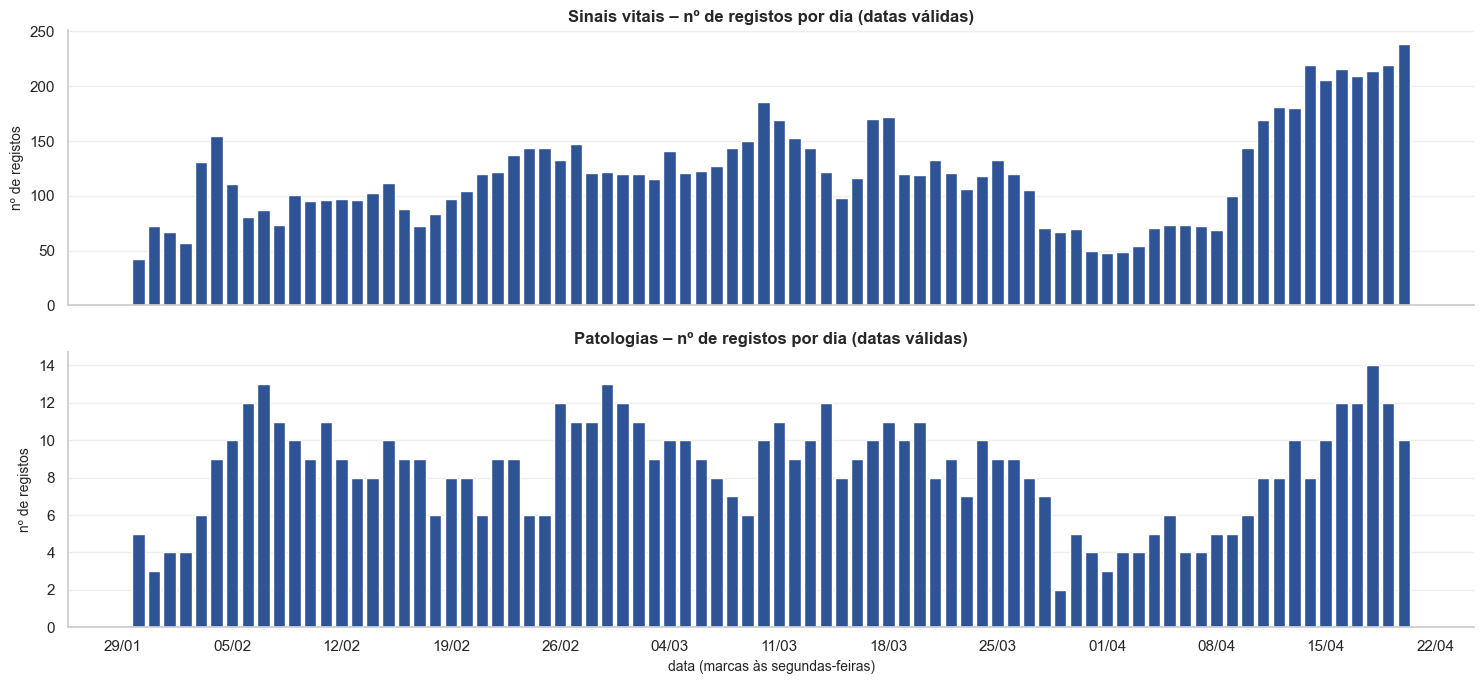

In [13]:
# =============================================================================
# 2.2.4 Variável data
# Verifica se as datas são válidas e estão no formato AAAA-MM-DD. A conversão
# para data é feita só para verificar (os dados não são alterados): os valores
# que não convertem são listados com o nº de ocorrências.
# Para as datas válidas, mostra o período coberto, o nº de dias distintos e
# um gráfico com o nº de registos em cada dia (Passo 6).
# =============================================================================
for nome, df in [("Sinais vitais", df_sinais), ("Patologias", df_patologias)]:
    convertida = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")
    invalida = convertida.isna() & df["data"].notna()

    print(f"\n===== {nome} =====")
    print(f"Datas válidas: {(~invalida).sum()} registos | inválidas: {invalida.sum()} registos")
    print(f"Período das datas válidas: {convertida.min().date()} a {convertida.max().date()} "
          f"({(convertida.max() - convertida.min()).days + 1} dias de calendário)")
    print(f"Dias distintos com registos (datas válidas): {convertida.nunique()}")

    print("Valores inválidos (tal como estão escritos):")
    display(df.loc[invalida, "data"].value_counts().to_frame("registos"))

# --- Visualização (Passo 6): nº de registos por dia (datas válidas), nas duas tabelas
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for k, (nome, df) in enumerate([("Sinais vitais", df_sinais), ("Patologias", df_patologias)]):
    convertida = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")
    por_dia = convertida.value_counts().sort_index()
    axes[k].bar(por_dia.index, por_dia.values, width=0.8, color=AZUL)
    axes[k].set_title(f"{nome} – nº de registos por dia (datas válidas)")
    axes[k].set_ylabel("nº de registos")
    axes[k].grid(axis="x", visible=False)
    axes[k].yaxis.get_major_locator().set_params(integer=True)
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
axes[1].set_xlabel("data (marcas às segundas-feiras)")
plt.tight_layout()
plt.show()


Valores distintos: 27 | mínimo: -1 | máximo: 25
Registos fora do domínio (0 a 23): 8


,registos
hora,
-1,5
24,2
25,1


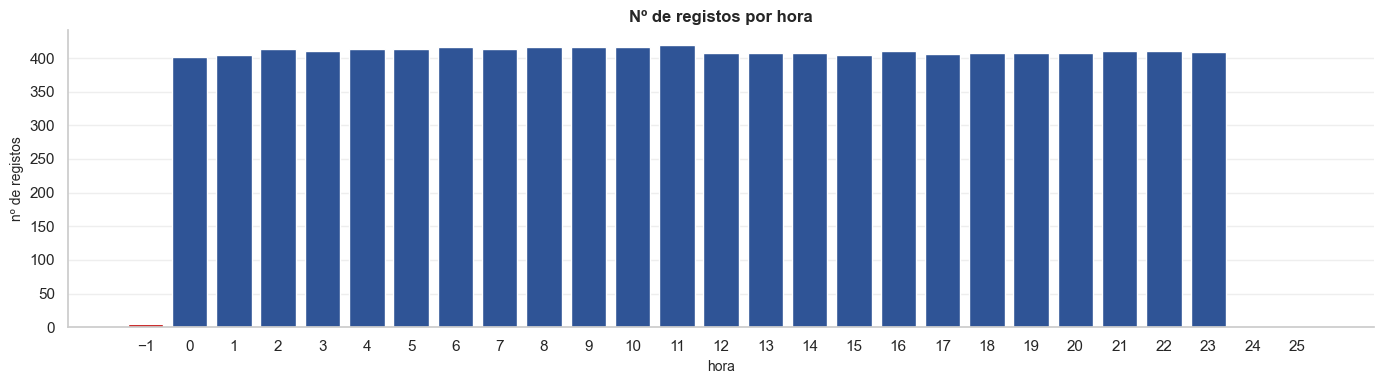

Nas horas 0 a 23: entre 401 e 420 registos por hora


In [14]:
# =============================================================================
# 2.2.5 Variável hora
# Domínio esperado: inteiros de 0 a 23.
# - Lista os valores fora do domínio e o nº de registos de cada um
# - Estatísticas básicas (Passo 4) e gráfico de barras com o nº de registos
#   por hora (Passo 6); as barras fora do domínio aparecem a vermelho
# Os dados não são alterados.
# =============================================================================
hora = df_sinais["hora"]
fora = ~hora.between(0, 23)

print(f"Valores distintos: {hora.nunique()} | mínimo: {hora.min()} | máximo: {hora.max()}")
print(f"Registos fora do domínio (0 a 23): {fora.sum()}")
display(hora[fora].value_counts().sort_index().to_frame("registos"))

contagem = hora.value_counts().sort_index()
cores = [VERMELHO if not 0 <= h <= 23 else AZUL for h in contagem.index]

plt.figure(figsize=(14, 4))
plt.bar(contagem.index, contagem.values, color=cores)
plt.title("Nº de registos por hora")
plt.xlabel("hora")
plt.ylabel("nº de registos")
plt.xticks(contagem.index)
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

dentro = contagem[(contagem.index >= 0) & (contagem.index <= 23)]
print(f"Nas horas 0 a 23: entre {dentro.min()} e {dentro.max()} registos por hora")

In [15]:
# =============================================================================
# 2.2.6 Sinais vitais: valores não numéricos e estatísticas (Passo 4)
# A conversão para número é feita só para calcular (os dados não são
# alterados): os valores que não convertem são listados tal como estão
# escritos e ficam de fora das estatísticas.
# Estatísticas: nº de valores numéricos, média, mediana, moda, desvio padrão,
# coeficiente de variação, mínimo, quartis, máximo, assimetria e curtose.
# =============================================================================
VITAIS = ["sat_o2", "puls_rate", "perfusion"]
num = df_sinais[VITAIS].apply(pd.to_numeric, errors="coerce")   # cópia temporária

for col in VITAIS:
    nao_num = df_sinais.loc[num[col].isna() & df_sinais[col].notna(), col]
    print(f"{col}: {len(nao_num)} valores não numéricos -> {[repr(v) for v in nao_num.unique()]}")

estat = num.describe().T
estat["mediana"] = num.median()
estat["moda"] = num.mode().iloc[0]
estat["cv_%"] = estat["std"] / estat["mean"] * 100
estat["assimetria"] = num.skew()
estat["curtose"] = num.kurt()
display(estat[["count", "mean", "mediana", "moda", "std", "cv_%", "min", "25%", "75%", "max",
               "assimetria", "curtose"]].round(2))

sat_o2: 3 valores não numéricos -> ["'97,57'", "'94,09'", "'95,6'"]
puls_rate: 7 valores não numéricos -> ["'118,64'", "'114,84'", "'164,24'", "'162,53'", "'136,17'", "'158,65'", "'138,29'"]
perfusion: 5 valores não numéricos -> ["'1,92'", "'1,16'", "'1,63'", "'1,29'", "'1,43'"]


,count,mean,mediana,moda,std,cv_%,min,25%,75%,max,assimetria,curtose
sat_o2,9810.0,96.25,96.27,96.98,14.05,14.59,-5.0,94.67,97.63,999.0,55.01,3492.09
puls_rate,9786.0,148.11,149.38,157.96,24.13,16.29,-10.0,138.96,158.17,999.0,19.01,652.05
perfusion,9810.0,1.30,1.15,1.06,2.52,193.66,-1.0,0.91,1.44,99.0,33.21,1216.25


sat_o2: 189 valores fora do zoom do histograma (abaixo de P1 ou acima de P99) | bigodes entre 90.24 e 101.00
puls_rate: 196 valores fora do zoom do histograma (abaixo de P1 ou acima de P99) | bigodes entre 110.25 e 185.58
perfusion: 188 valores fora do zoom do histograma (abaixo de P1 ou acima de P99) | bigodes entre 0.26 e 2.23


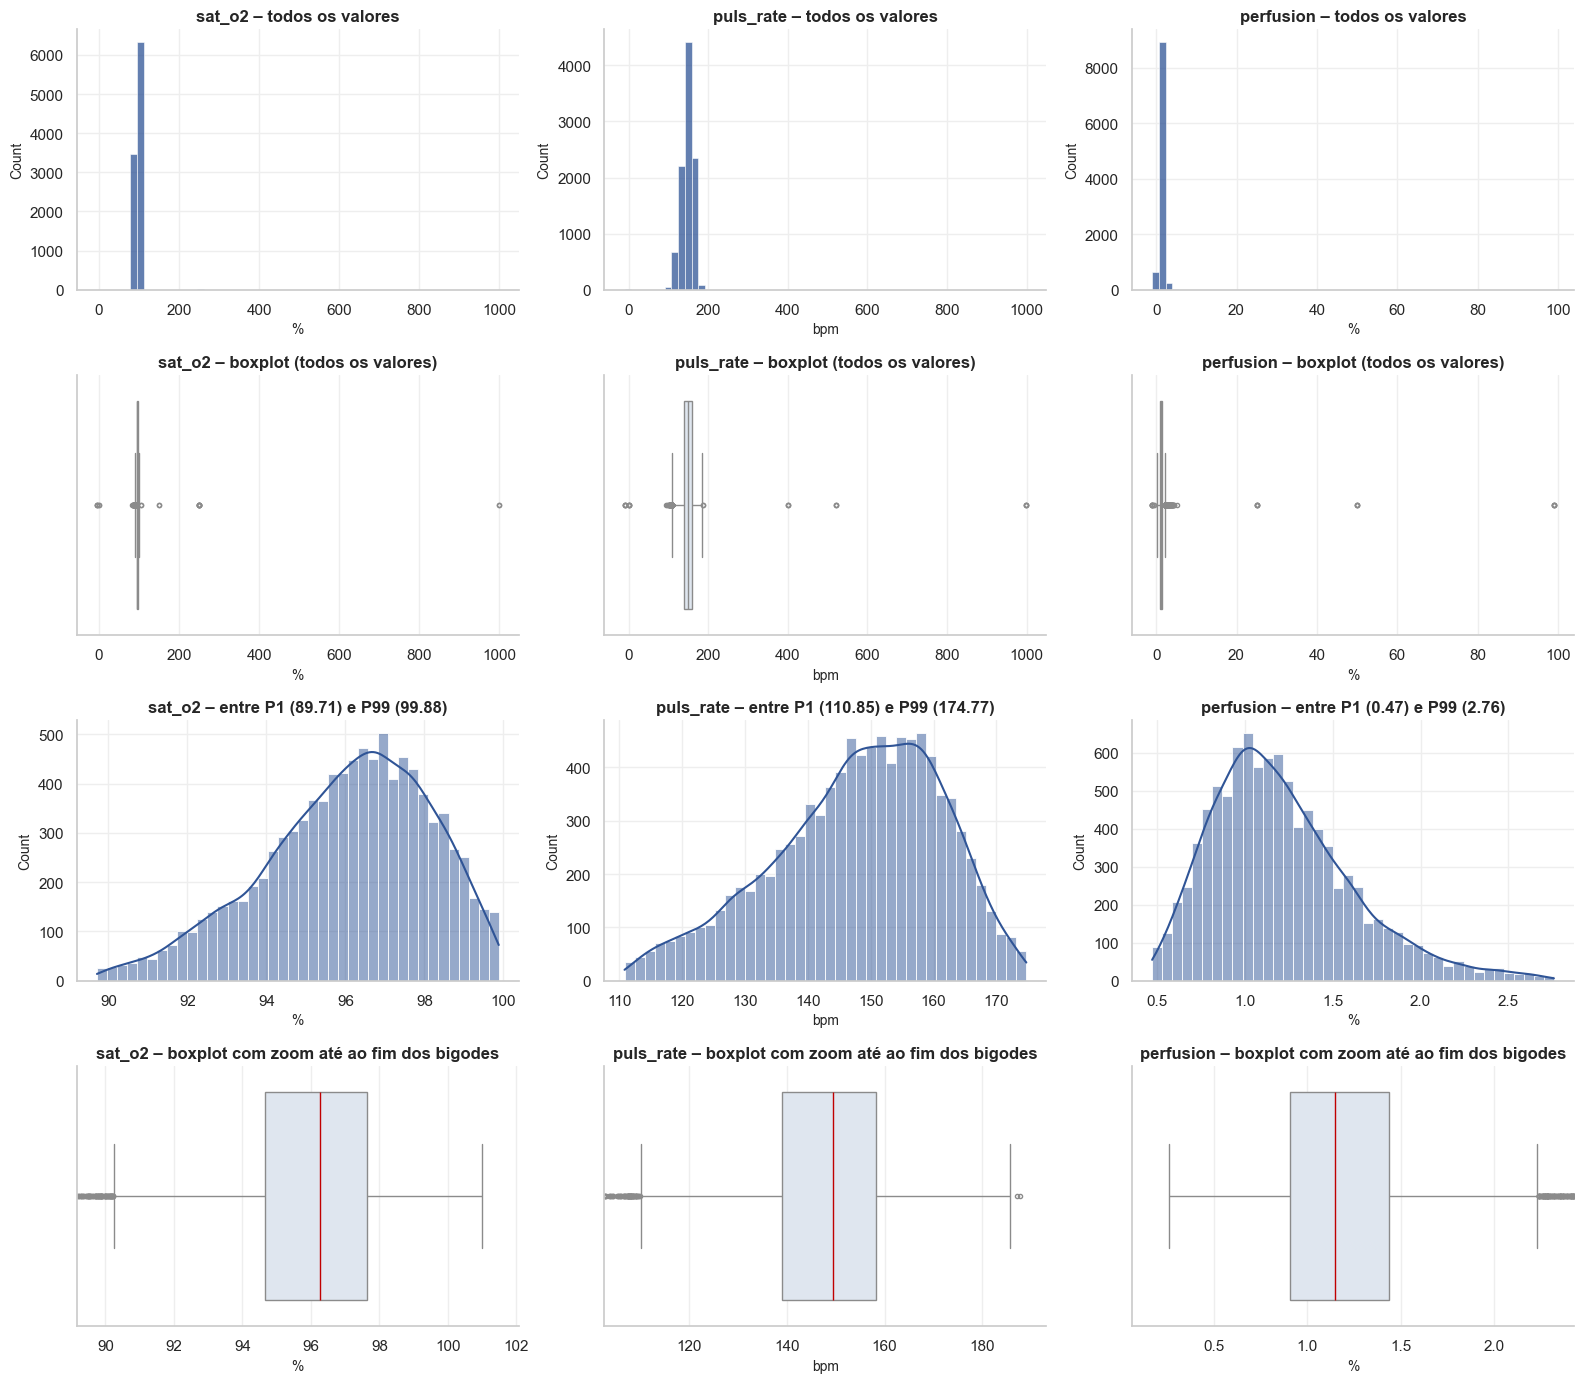

In [16]:
# =============================================================================
# 2.2.7 Sinais vitais: gráficos (Passo 6)
# Linha 1: histograma com todos os valores numéricos
# Linha 2: boxplot com todos os valores (mostra os valores extremos)
# Linha 3: histograma entre o percentil 1 e o percentil 99 (zoom nos 98% de
#          valores centrais, para ver a forma da distribuição)
# Linha 4: boxplot com todos os valores, com zoom no eixo até ao fim dos
#          bigodes (a caixa e a mediana são calculadas com todos os valores;
#          os valores fora do zoom continuam a existir, só não aparecem na vista)
# Usa a cópia temporária num da 2.2.6. Os dados não são alterados; os
# valores fora do zoom são apenas contados.
# =============================================================================
unidades = {"sat_o2": "%", "puls_rate": "bpm", "perfusion": "%"}
fig, axes = plt.subplots(4, 3, figsize=(16, 14))

for i, col in enumerate(VITAIS):
    valores = num[col].dropna()
    p1, p99 = valores.quantile([0.01, 0.99])

    # Linha 1: histograma com todos os valores
    sns.histplot(valores, bins=60, ax=axes[0, i], color=AZUL)
    axes[0, i].set_title(f"{col} – todos os valores")

    # Linha 2: boxplot com todos os valores
    sns.boxplot(x=valores, ax=axes[1, i], color=AZUL_CLARO, flierprops={"markersize": 3})
    axes[1, i].set_title(f"{col} – boxplot (todos os valores)")

    # Linha 3: histograma entre P1 e P99
    centro = valores[valores.between(p1, p99)]
    sns.histplot(centro, bins=40, kde=True, ax=axes[2, i], color=AZUL)
    axes[2, i].set_title(f"{col} – entre P1 ({p1:.2f}) e P99 ({p99:.2f})")

    # Linha 4: boxplot com zoom até ao fim dos bigodes (regra de 1,5 × IQR)
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    bigode_esq = valores[valores >= q1 - 1.5 * iqr].min()
    bigode_dir = valores[valores <= q3 + 1.5 * iqr].max()
    folga = (bigode_dir - bigode_esq) * 0.10

    sns.boxplot(x=valores, ax=axes[3, i], color=AZUL_CLARO, flierprops={"markersize": 3},
                medianprops={"color": VERMELHO})
    axes[3, i].set_xlim(bigode_esq - folga, bigode_dir + folga)
    axes[3, i].set_title(f"{col} – boxplot com zoom até ao fim dos bigodes")

    for linha in range(4):
        axes[linha, i].set_xlabel(unidades[col])
    print(f"{col}: {len(valores) - len(centro)} valores fora do zoom do histograma (abaixo de P1 ou acima de P99) "
          f"| bigodes entre {bigode_esq:.2f} e {bigode_dir:.2f}")

plt.tight_layout()
plt.show()

Valores distintos: 25 | coincidem com nomes oficiais: 10


,valor,registos,nome oficial
0,'Doença das membranas hialinas',264,sim
1,'Icterícia neonatal',159,sim
2,'Anemia',52,sim
3,'Citomegalovírus',49,sim
4,'Displasia broncopulmonar',35,sim
5,'Persistência do canal arterial',31,sim
6,'Refluxo gastroesofágico',26,sim
7,'Sépsis',18,sim
8,nan,12,não
9,'Doenca das membranas hialinas',9,não


Patologias oficiais sem nenhum registo: ['Hemorragia peri-intraventricular', 'Enterocolite necrosante', 'Doença metabólica óssea da prematuridade']


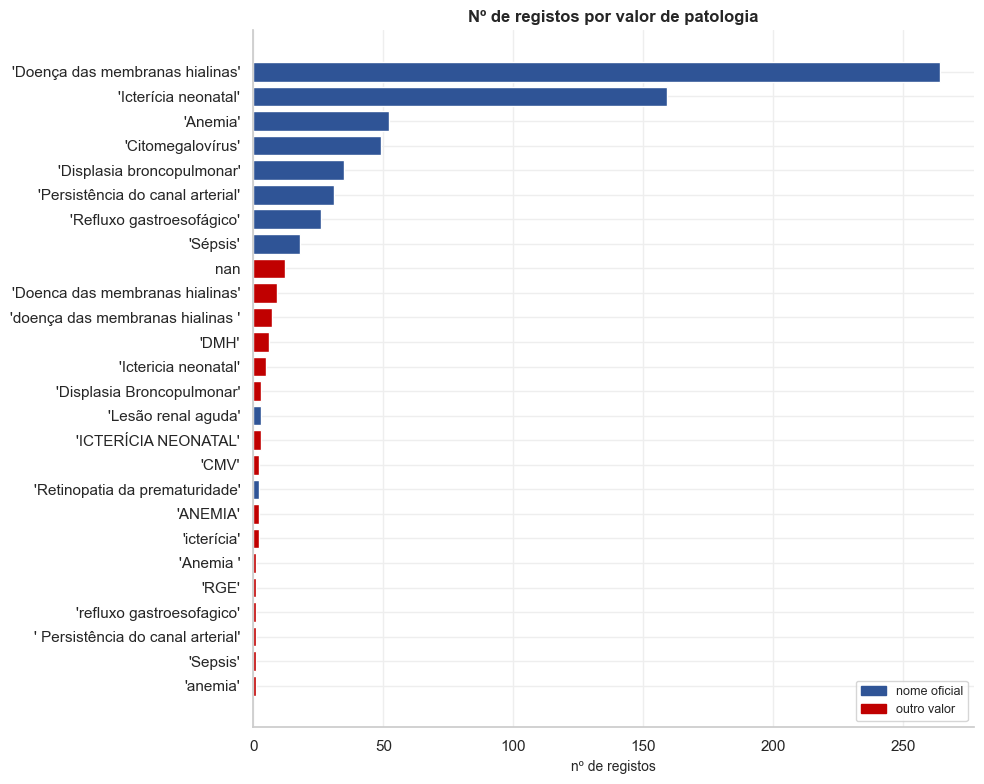

In [17]:
# =============================================================================
# 2.2.8 Variável patologia
# Compara os valores observados com os 13 nomes oficiais do dicionário de
# dados (comparação exata, tal como estão escritos).
# - Tabela com todos os valores, nº de registos e se coincidem com um nome
#   oficial; os valores aparecem entre aspas para tornar visíveis os espaços
# - Lista das patologias oficiais sem nenhum registo
# - Gráfico de barras (Passo 6): azul = nome oficial, vermelho = outro valor
# Os dados não são alterados.
# =============================================================================
OFICIAIS = ["Sépsis", "Hemorragia peri-intraventricular", "Lesão renal aguda",
            "Persistência do canal arterial", "Anemia", "Enterocolite necrosante",
            "Displasia broncopulmonar", "Retinopatia da prematuridade",
            "Icterícia neonatal", "Doença das membranas hialinas",
            "Doença metabólica óssea da prematuridade", "Citomegalovírus",
            "Refluxo gastroesofágico"]

freq = df_patologias["patologia"].value_counts(dropna=False)
tabela = pd.DataFrame({
    "valor": [repr(v) for v in freq.index],
    "registos": freq.values,
    "nome oficial": ["sim" if v in OFICIAIS else "não" for v in freq.index],
})
print(f"Valores distintos: {df_patologias['patologia'].nunique()} | "
      f"coincidem com nomes oficiais: {(tabela['nome oficial'] == 'sim').sum()}")
display(tabela)

sem_registos = [p for p in OFICIAIS if p not in freq.index]
print("Patologias oficiais sem nenhum registo:", sem_registos)

plt.figure(figsize=(10, 8))
cores = [AZUL if o == "sim" else VERMELHO for o in tabela["nome oficial"]]
plt.barh(tabela["valor"], tabela["registos"], color=cores)
plt.gca().invert_yaxis()
plt.title("Nº de registos por valor de patologia")
plt.legend(handles=[Patch(color=AZUL, label="nome oficial"), Patch(color=VERMELHO, label="outro valor")],
           loc="lower right", fontsize=9)
plt.xlabel("nº de registos")
plt.tight_layout()
plt.show()

### Relatório de Descrição dos Dados

**Formato e quantidade**

| Tabela | Registos | Campos | Granularidade | Período (datas válidas) |
|---|---|---|---|---|
| Sinais vitais | 9 857 | 6 | Episódio × dia × hora | 30/01/2024 a 20/04/2024 (82 dias) |
| Patologias | 696 | 3 | Episódio × dia × patologia | 30/01/2024 a 20/04/2024 (82 dias) |

Ambas as tabelas têm registos em todos os 82 dias do período.

**Descrição por variável (observado vs. esperado)**

| Variável | Tipo atribuído | Em falta | Distintos | Observações face ao dicionário de dados |
|---|---|---|---|---|
| episodio | texto | 0 | 58 (sinais) / 45 (patologias) | 47 e 39 códigos no formato EPnnn. 11 códigos (12 registos) nos sinais vitais e 6 (6 registos) nas patologias estão fora do formato: espaço no início, espaço no meio ou minúsculas. O nº de registos por código varia muito (mediana de 80 registos horários; máximo de 852) |
| data | texto | 0 | 97 (sinais) / 91 (patologias) | 18 datas inválidas nos sinais vitais e 10 nas patologias: formato DD/MM/AAAA, mês inválido (ex.: "2024-13-02") e datas impossíveis (ex.: "2024-02-31") |
| hora | inteiro | 0 | 27 | 8 registos fora do domínio 0–23: −1 (5), 24 (2) e 25 (1). Nas horas válidas, a distribuição é uniforme (401 a 420 registos por hora) |
| sat_o2 | texto | 44 (0,45 %) | 1 044 | 3 valores com vírgula decimal. Valores fora do domínio 0–100 (mínimo −5, máximo 999) |
| puls_rate | texto | 64 (0,65 %) | 4 399 | 7 valores com vírgula decimal. Valores impossíveis (mínimo −10, máximo 999; também 400 e 520) |
| perfusion | texto | 42 (0,43 %) | 315 | 5 valores com vírgula decimal. Valores negativos (−1) e muito elevados (25, 50, 99) |
| patologia | texto | 12 (1,72 %) | 25 | Só 10 valores coincidem com os 13 nomes oficiais. Os restantes 15 (45 registos) são variantes desses nomes: sem acentos, maiúsculas/minúsculas, espaços a mais, siglas (DMH, CMV, RGE) e nomes incompletos. Três patologias oficiais não têm registos: hemorragia peri-intraventricular, enterocolite necrosante e doença metabólica óssea da prematuridade |

**Estatísticas dos sinais vitais (valores numéricos)**

| Variável | Mediana | Q1 – Q3 | P1 – P99 | Mínimo | Máximo | Forma da distribuição (P1–P99) |
|---|---|---|---|---|---|---|
| sat_o2 (%) | 96,27 | 94,67 – 97,63 | 89,71 – 99,88 | −5 | 999 | Pico perto de 97 %, cauda à esquerda, limite natural em 100 % |
| puls_rate (bpm) | 149,38 | 138,96 – 158,17 | 110,85 – 174,77 | −10 | 999 | Pico entre 145 e 160 bpm, cauda à esquerda |
| perfusion (%) | 1,15 | 0,91 – 1,44 | 0,47 – 2,76 | −1 | 99 | Pico perto de 1 %, cauda à direita |

As medianas e os quartis são clinicamente plausíveis. Um pequeno número de valores extremos, concentrados em valores concretos e repetidos (como 999, 99, 400, 520, 25 e 50, e valores negativos), distorce a média, o desvio padrão, a assimetria e a curtose (por exemplo, desvio padrão de 14,05 na saturação, quando o intervalo interquartil é de cerca de 3 pontos). Por isso, nesta fase, a mediana e os quartis são as medidas mais fiáveis.

Pela regra do intervalo interquartil (1,5 × IQR), os bigodes vão de 90,24 % a 101,00 % na saturação, de 110,25 a 185,58 bpm no pulso e de 0,26 % a 2,23 % na perfusão. Esta regra não deteta todos os valores impossíveis (há saturações ligeiramente acima de 100 % dentro dos bigodes) e assinala como outliers valores plausíveis nas caudas das distribuições assimétricas, sobretudo valores altos de perfusão e baixos de pulso. Por isso, a identificação de outliers na tarefa 2.4 combinará o domínio de cada variável com critérios estatísticos.

**Patologias**

A distribuição das patologias é muito desequilibrada: a doença das membranas hialinas e a icterícia neonatal concentram a maioria dos registos, enquanto a lesão renal aguda (3 registos) e a retinopatia da prematuridade (2) são muito raras.

**Os dados satisfazem os requisitos do projeto?**

| Requisito | Avaliação |
|---|---|
| Dados para a classificação de patologias (DM1) | **Parcialmente.** Existem sinais vitais e patologias por dia para os mesmos episódios, mas só 10 das 13 patologias estão presentes e algumas têm 2 ou 3 registos |
| Dados para a regressão da duração do internamento (DM2) | **Parcialmente.** Não existe uma variável de duração do internamento; terá de ser construída a partir das datas dos sinais vitais (Fase 3) |
| Dados para o clustering de episódios (DM3) | **Sim**, os episódios podem ser caracterizados pelos sinais vitais e pelas patologias |
| Qualidade | Foram identificados problemas de formato, valores fora do domínio, valores em falta e inconsistências de escrita, analisados em detalhe na tarefa 2.4 |

## 2.3 Exploração dos Dados (Explore Data)
> **CRISP-DM:** responder a questões de data mining através de consultas, visualizações e relatórios: distribuição dos atributos-chave, relações entre pares de atributos, resultados de agregações simples, propriedades de subpopulações e análises estatísticas simples. Output: *Data Exploration Report*, com os primeiros resultados, as hipóteses iniciais e o seu impacto no resto do projeto.
>
> **Passos EDA:** 5 – Transformação dos dados (para explorar); 8 – Reportar.

As agregações e cálculos desta secção servem apenas para explorar: os dados não são alterados, e os valores são usados tal como foram fornecidos (incluindo códigos de episódio e datas tal como estão escritos).

Linhas totalmente repetidas: 60
Combinações episódio+data+hora repetidas: 60

Pares (código de episódio, data): 478


,nº de pares episódio-data
1 a 12 horas,66
13 a 23 horas,77
24 horas,291
mais de 24,44


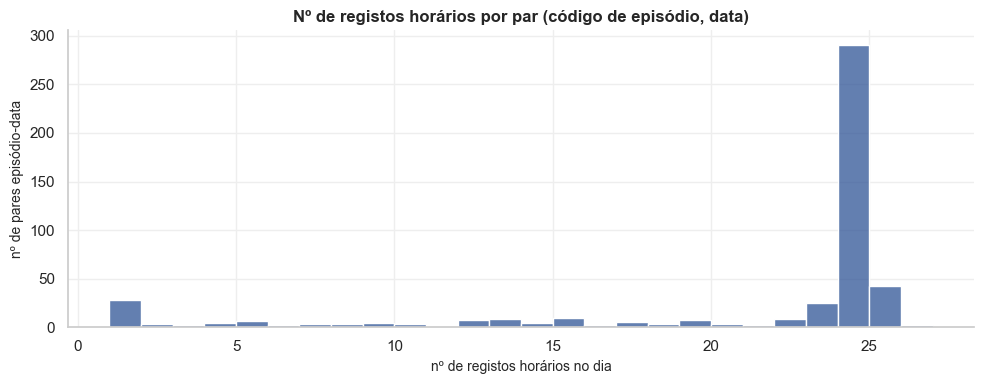

In [18]:
# =============================================================================
# 2.3.1 Registos por episódio e dia (sinais vitais)
# Verifica a granularidade "uma linha por episódio, dia e hora":
# - linhas totalmente repetidas e combinações episódio+data+hora repetidas
# - nº de registos horários em cada par (código de episódio, data), tal como
#   estão escritos: 24 = dia completo; menos = dia parcial; mais = repetição
# Os dados não são alterados.
# =============================================================================
chave = ["episodio", "data", "hora"]
print("Linhas totalmente repetidas:", df_sinais.duplicated().sum())
print("Combinações episódio+data+hora repetidas:", df_sinais.duplicated(subset=chave).sum())

horas_por_dia = df_sinais.groupby(["episodio", "data"]).size()
print(f"\nPares (código de episódio, data): {len(horas_por_dia)}")

categorias = pd.cut(horas_por_dia, bins=[0, 12, 23, 24, np.inf],
                    labels=["1 a 12 horas", "13 a 23 horas", "24 horas", "mais de 24"])
display(categorias.value_counts().sort_index().to_frame("nº de pares episódio-data"))

plt.figure(figsize=(10, 4))
sns.histplot(horas_por_dia, bins=range(1, int(horas_por_dia.max()) + 2), color=AZUL)
plt.title("Nº de registos horários por par (código de episódio, data)")
plt.xlabel("nº de registos horários no dia")
plt.ylabel("nº de pares episódio-data")
plt.tight_layout()
plt.show()

Linhas totalmente repetidas: 15

Pares (código de episódio, data): 458


,nº de pares episódio-data
1,272
2,141
3,38
4,7


Pares com 2 ou mais linhas: 186 (40.6%)


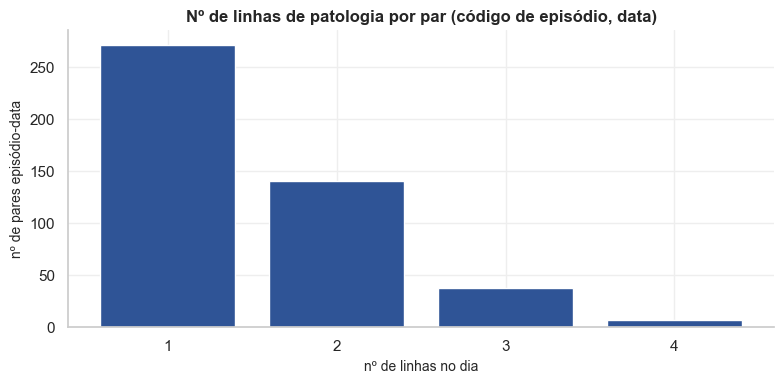

In [19]:
# =============================================================================
# 2.3.2 Registos de patologia por episódio e dia
# Verifica a granularidade "uma linha por patologia, episódio e dia":
# - linhas totalmente repetidas
# - nº de linhas em cada par (código de episódio, data), tal como estão
#   escritos: mostra quantas patologias são registadas por dia
# Nota: com os dados tal como estão, variantes do mesmo nome contam como
# patologias diferentes e as linhas sem patologia também são contadas.
# Os dados não são alterados.
# =============================================================================
print("Linhas totalmente repetidas:", df_patologias.duplicated().sum())

linhas_por_dia = df_patologias.groupby(["episodio", "data"]).size()
print(f"\nPares (código de episódio, data): {len(linhas_por_dia)}")

dist = linhas_por_dia.value_counts().sort_index()
display(dist.to_frame("nº de pares episódio-data"))
print(f"Pares com 2 ou mais linhas: {(linhas_por_dia >= 2).sum()} "
      f"({(linhas_por_dia >= 2).mean():.1%})")

plt.figure(figsize=(8, 4))
plt.bar(dist.index, dist.values, color=AZUL)
plt.title("Nº de linhas de patologia por par (código de episódio, data)")
plt.xlabel("nº de linhas no dia")
plt.ylabel("nº de pares episódio-data")
plt.xticks(dist.index)
plt.tight_layout()
plt.show()

Registos usados: 9827 de 9857 (30 com código fora do formato ou data inválida)

Episódios: 47


,dias_com_registos,dias_entre_primeiro_e_ultimo,dias_sem_registos
count,47.0,47.0,47.0
mean,9.6,9.7,0.1
std,8.2,8.3,0.6
min,1.0,1.0,0.0
25%,3.5,3.5,0.0
50%,7.0,7.0,0.0
75%,13.5,13.5,0.0
max,36.0,36.0,3.0


Episódios com dias sem registos entre o primeiro e o último dia:


,primeiro_dia,ultimo_dia,dias_com_registos,dias_sem_registos
episodio,,,,
EP004,2024-02-02,2024-02-27,23,3
EP006,2024-02-03,2024-02-15,10,3
EP007,2024-02-03,2024-02-07,4,1


Episódios que começam a 2024-01-30 ou acabam a 2024-04-20: 13


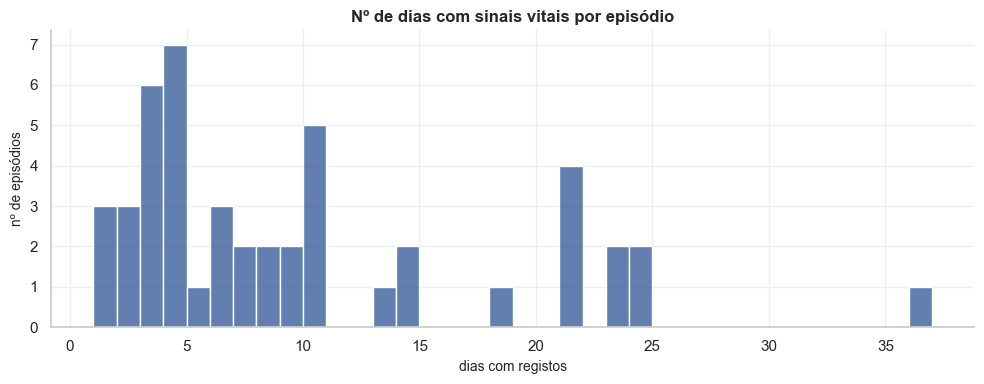

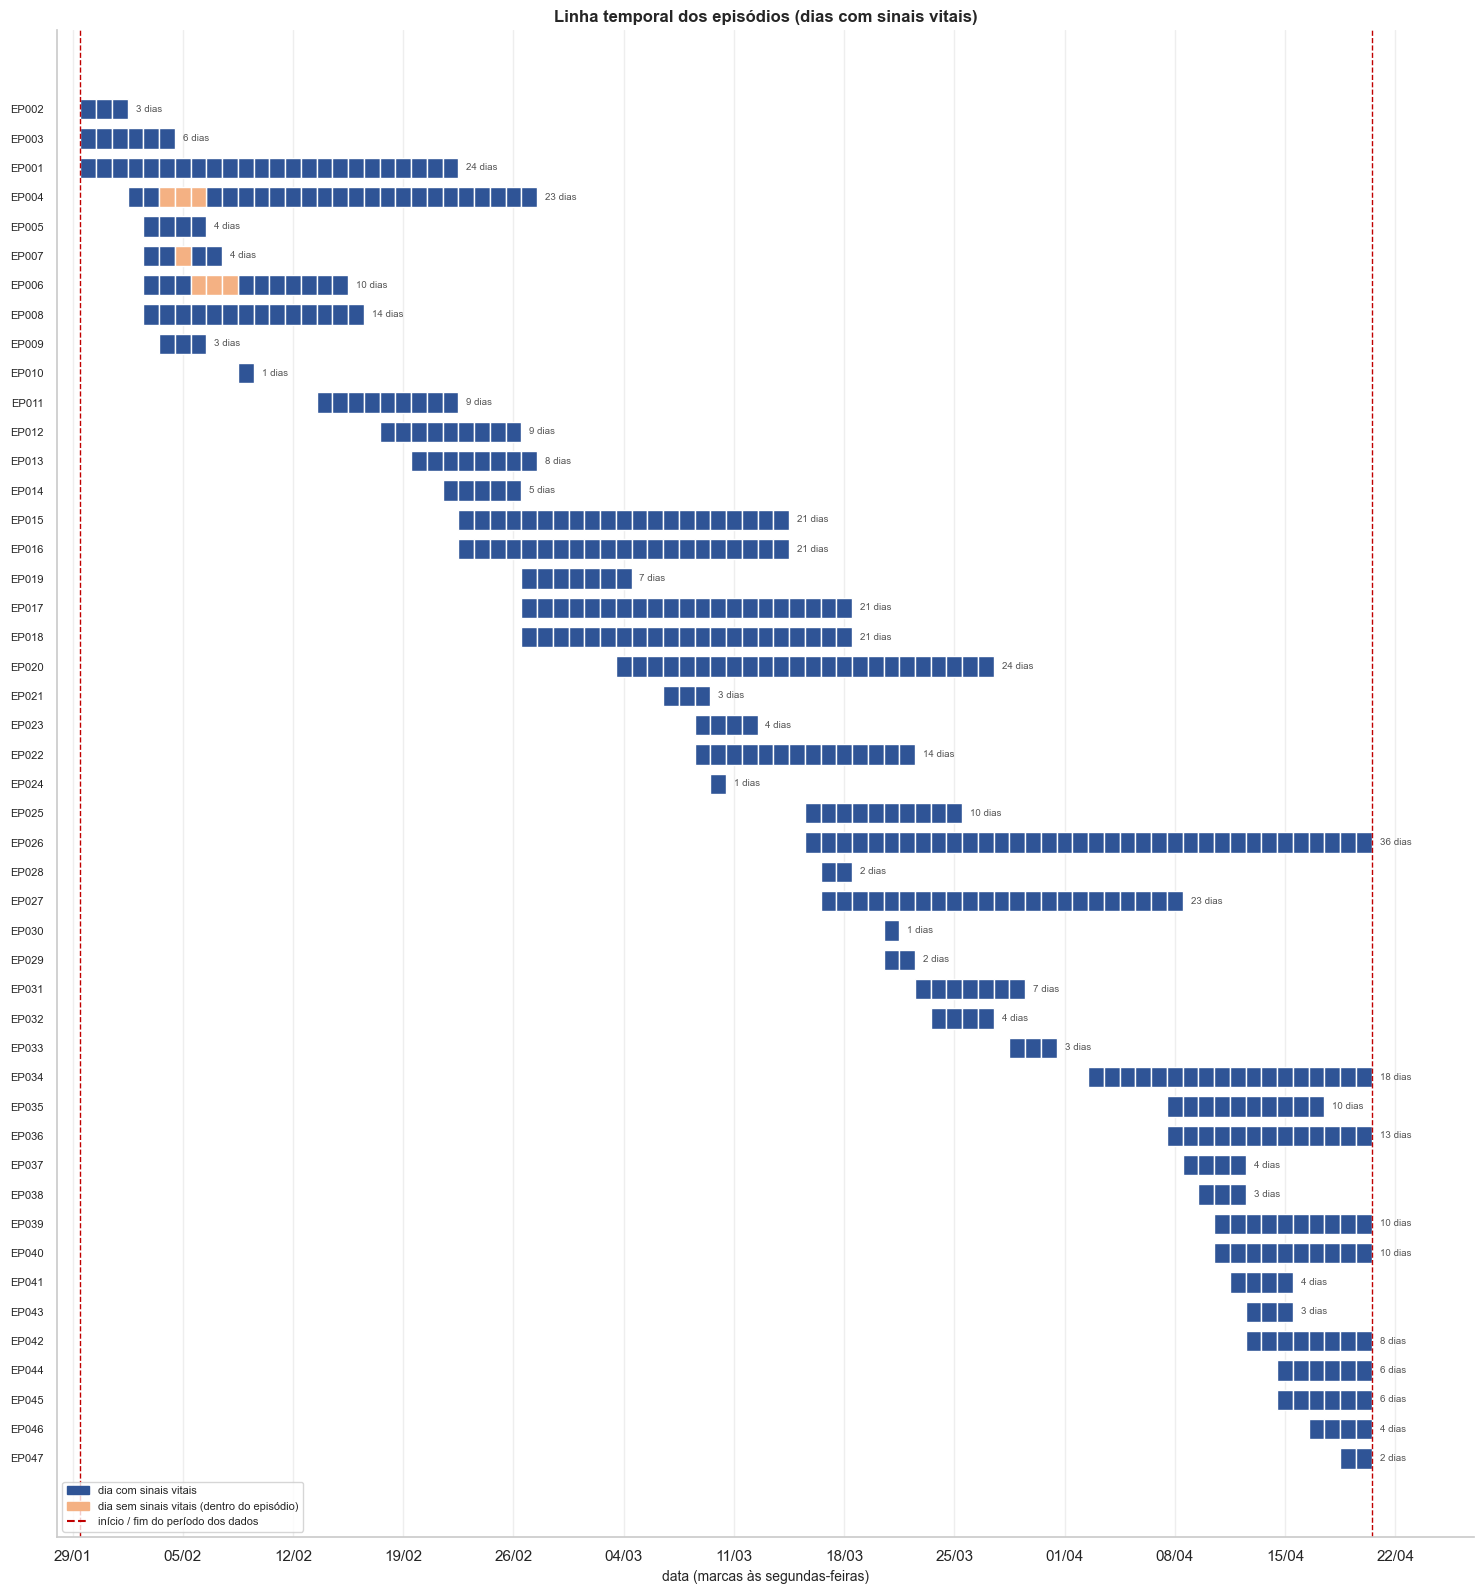

In [20]:
# =============================================================================
# 2.3.3 Dias com sinais vitais por episódio
# Para cada código de episódio: dias com registos de sinais vitais, primeira
# e última data e dias sem registos entre elas. No fim, uma linha temporal
# com os dias de cada episódio no calendário.
# Usa só os registos com código no formato EPnnn e data válida (os restantes
# são gralhas identificadas na 2.2 e são apenas contados). A conversão das
# datas é feita só para calcular; os dados não são alterados.
# =============================================================================
# --- Seleção dos registos com código e data válidos (só para esta análise)
cod_ok = df_sinais["episodio"].str.fullmatch(r"EP\d{3}")
datas = pd.to_datetime(df_sinais["data"], format="%Y-%m-%d", errors="coerce")
usados = cod_ok & datas.notna()
print(f"Registos usados: {usados.sum()} de {len(df_sinais)} "
      f"({(~usados).sum()} com código fora do formato ou data inválida)")

tmp = pd.DataFrame({"episodio": df_sinais["episodio"], "data": datas})[usados]

# --- Resumo por episódio
por_ep = tmp.groupby("episodio")["data"].agg(dias_com_registos="nunique", primeiro_dia="min", ultimo_dia="max")
por_ep["dias_entre_primeiro_e_ultimo"] = (por_ep["ultimo_dia"] - por_ep["primeiro_dia"]).dt.days + 1
por_ep["dias_sem_registos"] = por_ep["dias_entre_primeiro_e_ultimo"] - por_ep["dias_com_registos"]

print(f"\nEpisódios: {len(por_ep)}")
display(por_ep[["dias_com_registos", "dias_entre_primeiro_e_ultimo", "dias_sem_registos"]]
        .describe().round(1))

print("Episódios com dias sem registos entre o primeiro e o último dia:")
display(por_ep.loc[por_ep["dias_sem_registos"] > 0,
                   ["primeiro_dia", "ultimo_dia", "dias_com_registos", "dias_sem_registos"]])

inicio, fim = tmp["data"].min(), tmp["data"].max()
nas_pontas = (por_ep["primeiro_dia"] == inicio) | (por_ep["ultimo_dia"] == fim)
print(f"Episódios que começam a {inicio.date()} ou acabam a {fim.date()}: {nas_pontas.sum()}")

# --- Histograma: nº de dias com registos por episódio
plt.figure(figsize=(10, 4))
sns.histplot(por_ep["dias_com_registos"], bins=range(1, por_ep["dias_com_registos"].max() + 2),
             color=AZUL)
plt.title("Nº de dias com sinais vitais por episódio")
plt.xlabel("dias com registos")
plt.ylabel("nº de episódios")
plt.tight_layout()
plt.show()

# --- Linha temporal: um bloco por dia, do primeiro ao último dia de cada episódio
#     azul = dia com sinais vitais | laranja = dia sem sinais vitais (dentro do episódio)
dias_com = set(zip(tmp["episodio"], tmp["data"]))
ordem = por_ep.sort_values(["primeiro_dia", "ultimo_dia"]).index

grelha = pd.DataFrame(
    [(ep, d, (ep, d) in dias_com)
     for ep in ordem
     for d in pd.date_range(por_ep.loc[ep, "primeiro_dia"], por_ep.loc[ep, "ultimo_dia"])],
    columns=["episodio", "data", "com_registos"])
grelha["y"] = grelha["episodio"].map({ep: i for i, ep in enumerate(ordem)})
grelha["x"] = mdates.date2num(grelha["data"]) - 0.5      # cada bloco ocupa o dia inteiro

fig, ax = plt.subplots(figsize=(15, 0.3 * len(ordem) + 2))
for valor, cor in [(True, AZUL), (False, LARANJA)]:
    g = grelha[grelha["com_registos"] == valor]
    ax.barh(g["y"], width=1, left=g["x"], height=0.7, color=cor)
ax.grid(axis="y", visible=False)

for i, ep in enumerate(ordem):
    ax.text(mdates.date2num(por_ep.loc[ep, "ultimo_dia"]) + 1, i,
            f"{por_ep.loc[ep, 'dias_com_registos']} dias", va="center", fontsize=7, color=CINZA)

ax.axvline(mdates.date2num(inicio) - 0.5, color=VERMELHO, ls="--", lw=1)
ax.axvline(mdates.date2num(fim) + 0.5, color=VERMELHO, ls="--", lw=1)

ax.set_yticks(range(len(ordem)))
ax.set_yticklabels(ordem, fontsize=8)
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_xlim(mdates.date2num(inicio) - 2, mdates.date2num(fim) + 7)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=AZUL, label="dia com sinais vitais"),
                   Patch(color=LARANJA, label="dia sem sinais vitais (dentro do episódio)"),
                   Line2D([], [], color=VERMELHO, ls="--", label="início / fim do período dos dados")],
          loc="lower left", fontsize=8)
ax.set_title("Linha temporal dos episódios (dias com sinais vitais)")
ax.set_xlabel("data (marcas às segundas-feiras)")
plt.tight_layout()
plt.show()

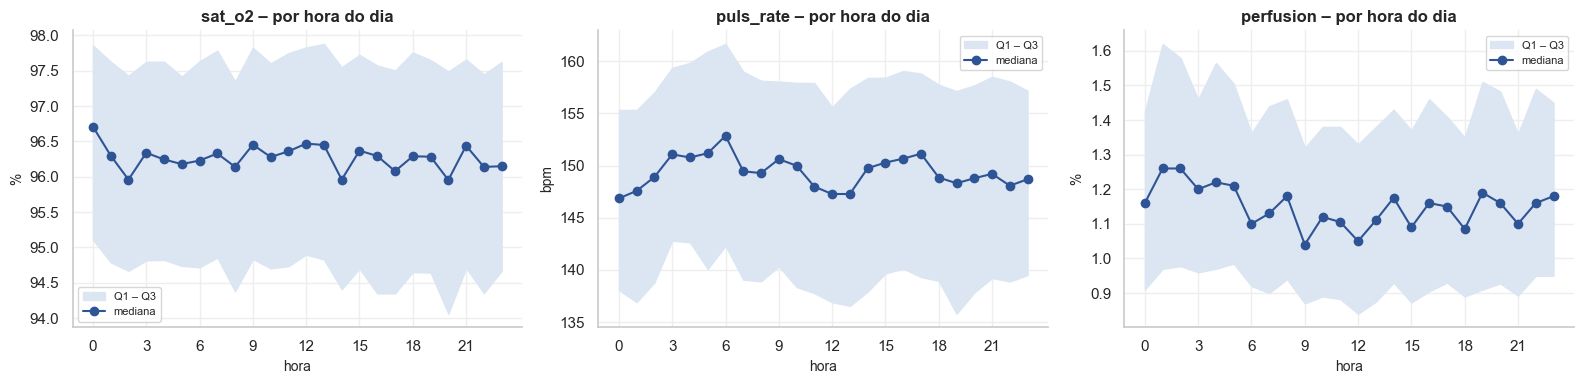

,min,max,variação da mediana,largura média Q1–Q3
sat_o2,95.96,96.71,0.75,2.98
puls_rate,146.85,152.84,6.00,19.08
perfusion,1.04,1.26,0.22,0.52


In [21]:
# =============================================================================
# 2.3.4 Sinais vitais ao longo do dia
# Mediana e intervalo Q1–Q3 de cada sinal vital em cada hora do dia.
# Usa a cópia temporária num da 2.2.6 (todos os valores numéricos, sem
# filtrar extremos): a mediana e os quartis são robustos a valores extremos.
# Mostra só as horas do domínio (0 a 23); os 8 registos com horas fora do
# domínio ficam de fora do gráfico. Os dados não são alterados.
# =============================================================================
por_hora = (num.assign(hora=df_sinais["hora"])
               .query("0 <= hora <= 23")
               .groupby("hora")[VITAIS]
               .quantile([0.25, 0.5, 0.75])
               .unstack())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, v in enumerate(VITAIS):
    axes[i].fill_between(por_hora.index, por_hora[(v, 0.25)], por_hora[(v, 0.75)],
                         color=AZUL_CLARO, label="Q1 – Q3")
    axes[i].plot(por_hora.index, por_hora[(v, 0.5)], marker="o", color=AZUL, label="mediana")
    axes[i].set_title(f"{v} – por hora do dia")
    axes[i].set_xlabel("hora")
    axes[i].set_ylabel(unidades[v])
    axes[i].set_xticks(range(0, 24, 3))
    axes[i].legend(fontsize=8)
plt.tight_layout()
plt.show()

amplitude = por_hora.xs(0.5, axis=1, level=1).agg(["min", "max"]).T
amplitude["variação da mediana"] = amplitude["max"] - amplitude["min"]
amplitude["largura média Q1–Q3"] = (por_hora.xs(0.75, axis=1, level=1) - por_hora.xs(0.25, axis=1, level=1)).mean()
display(amplitude.round(2))

Correlação de Spearman entre os sinais vitais:


,sat_o2,puls_rate,perfusion
sat_o2,1.00,-0.20,-0.19
puls_rate,-0.20,1.00,0.01
perfusion,-0.19,0.01,1.00


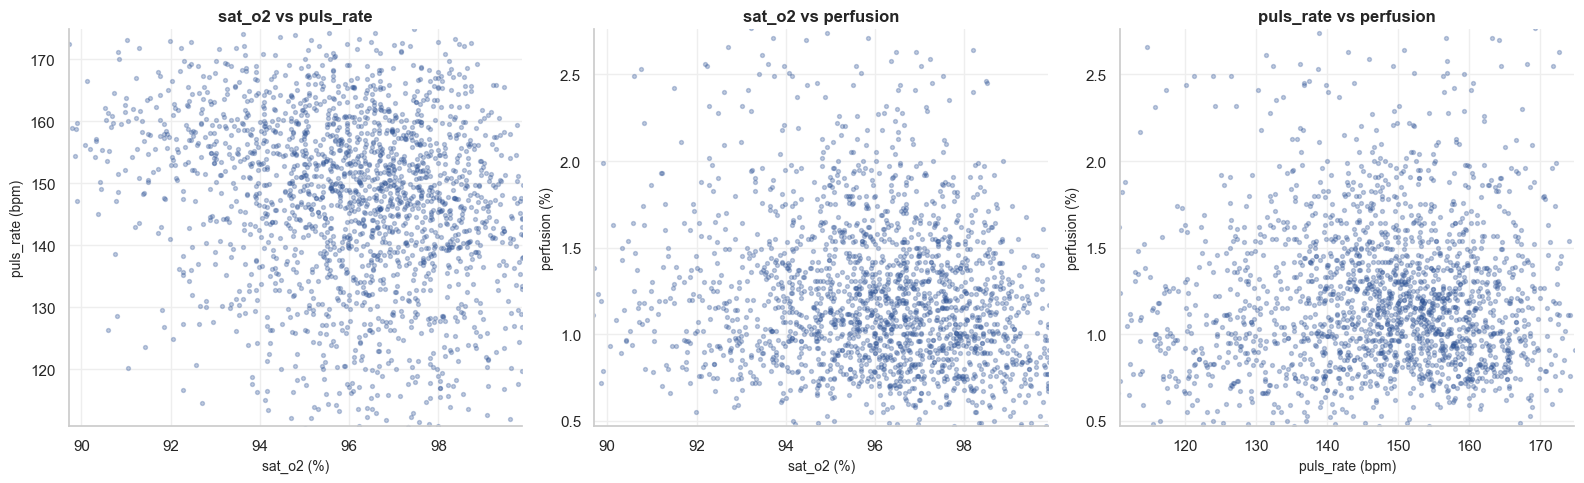

In [22]:
# =============================================================================
# 2.3.5 Relação entre os sinais vitais
# Pergunta: quando um sinal vital sobe, os outros também sobem ou descem?
# - Tabela de correlação de Spearman entre os três sinais vitais (de -1 a +1),
#   calculada com todos os valores numéricos (cópia temporária num da 2.2.6);
#   este coeficiente não é afetado pelos valores extremos (ex.: 999).
# - Um gráfico de pontos para cada par de sinais vitais, com uma amostra de
#   2 000 registos e zoom entre o percentil 1 e o 99 (vista apenas).
# Os dados não são alterados.
# =============================================================================
print("Correlação de Spearman entre os sinais vitais:")
display(num.corr(method="spearman").round(2))

amostra = num.dropna().sample(2000, random_state=42)
pares = [("sat_o2", "puls_rate"), ("sat_o2", "perfusion"), ("puls_rate", "perfusion")]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, (x, y) in enumerate(pares):
    axes[i].scatter(amostra[x], amostra[y], s=8, alpha=0.3, color=AZUL)
    axes[i].set_xlim(num[x].quantile([0.01, 0.99]))
    axes[i].set_ylim(num[y].quantile([0.01, 0.99]))
    axes[i].set_xlabel(f"{x} ({unidades[x]})")
    axes[i].set_ylabel(f"{y} ({unidades[y]})")
    axes[i].set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

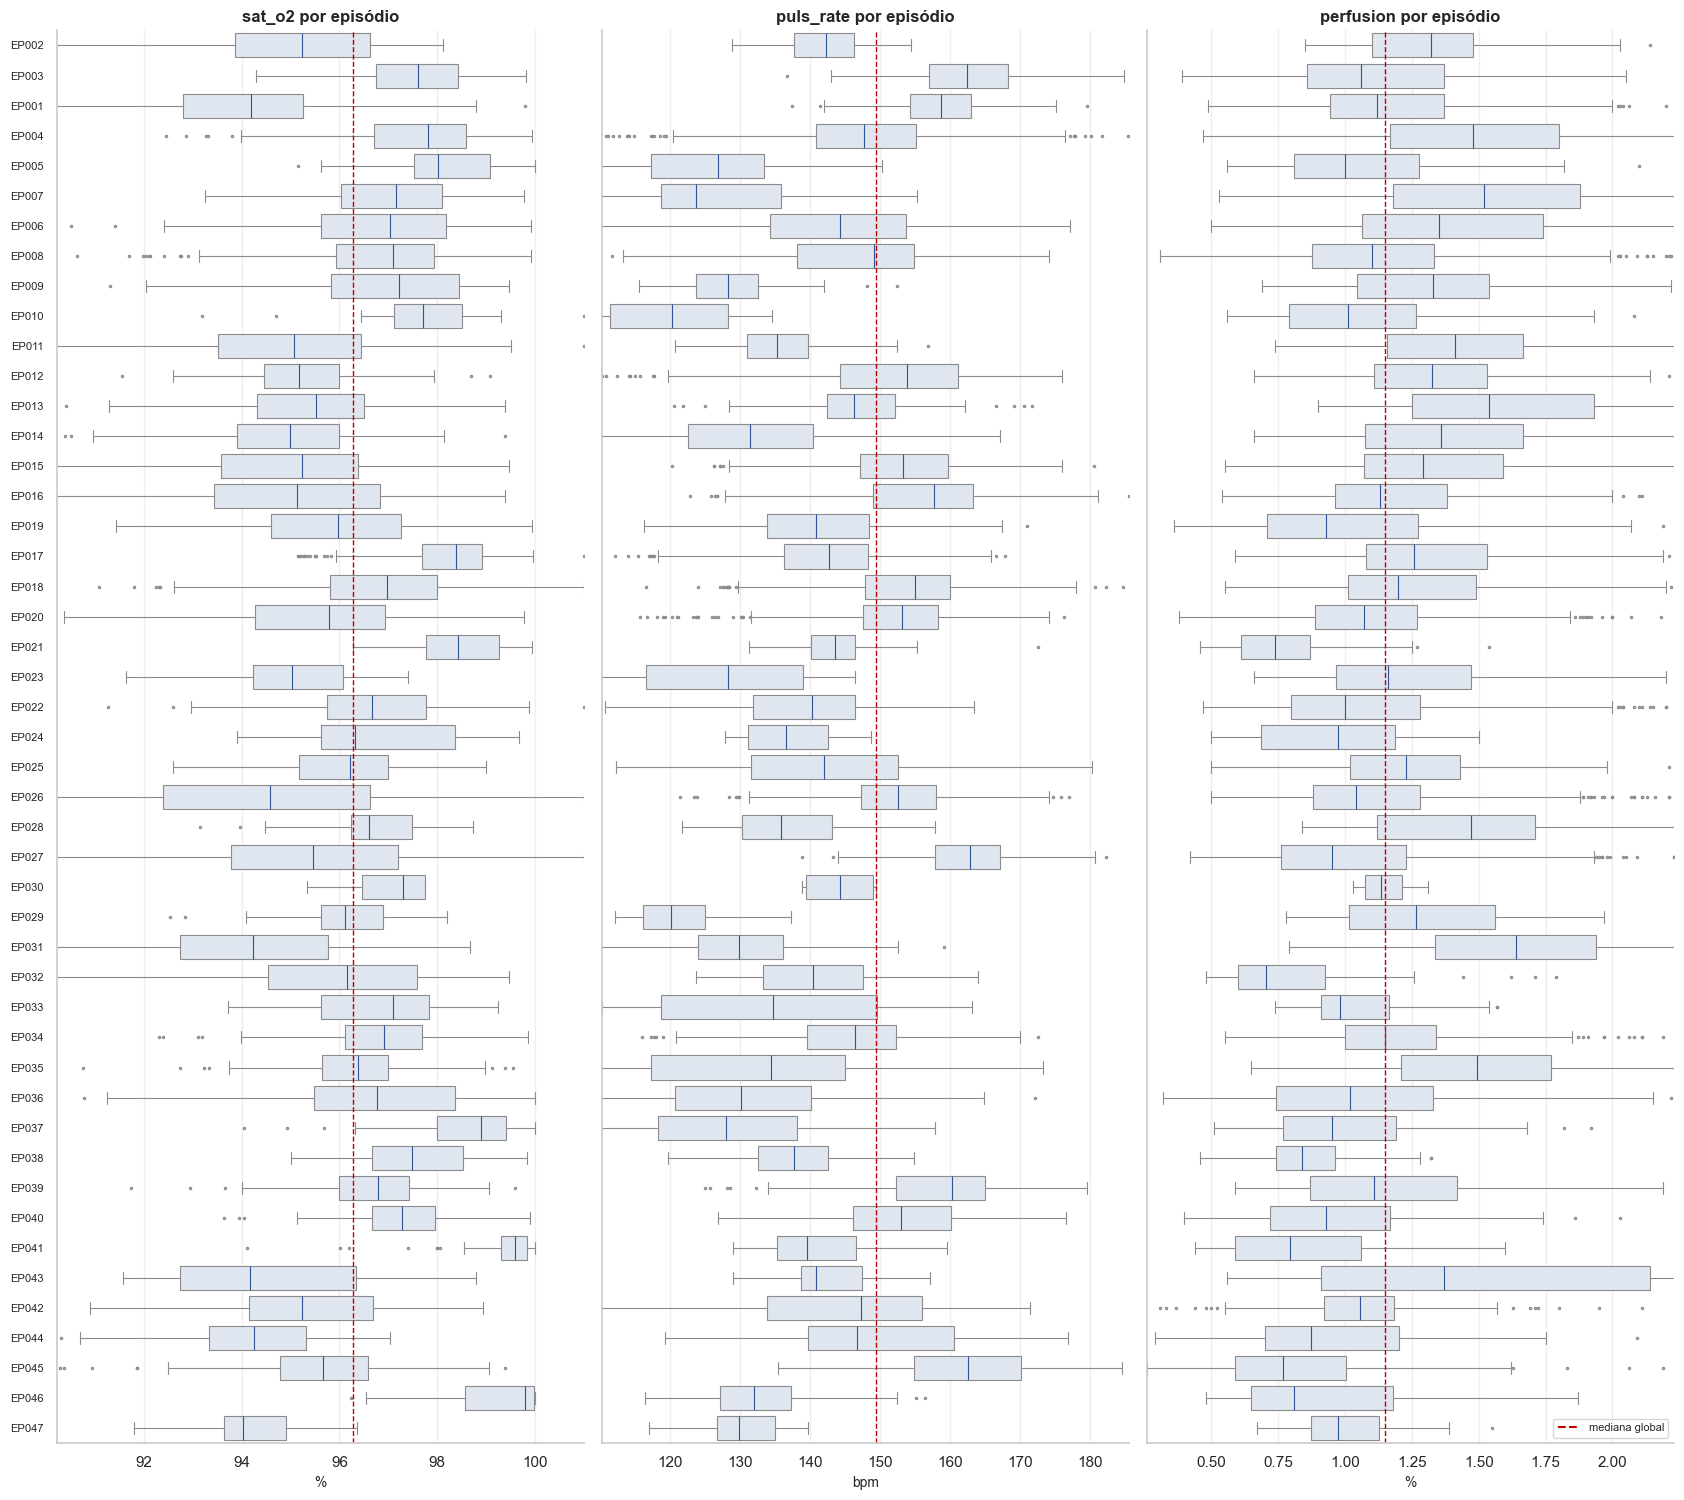

,mediana global,Q1–Q3 global,menor mediana de um episódio,maior mediana de um episódio,amplitude das medianas
sat_o2,96.27,94.66 – 97.63,94.02,99.79,5.77
puls_rate,149.38,138.94 – 158.18,120.14,162.90,42.77
perfusion,1.15,0.91 – 1.44,0.70,1.64,0.94


In [23]:
# =============================================================================
# 2.3.6 Sinais vitais por episódio
# Pergunta: os episódios têm níveis de sinais vitais diferentes entre si
# (cada bebé tem o seu "normal")?
# - Um boxplot por episódio para cada sinal vital, com os episódios pela mesma
#   ordem da linha temporal da 2.3.3 (data de início); zoom no eixo até ao fim
#   dos bigodes globais (vista apenas); linha vermelha = mediana global
# - Tabela: mediana global, intervalo Q1–Q3 global e variação das medianas
#   entre episódios
# Usa só os registos com código no formato EPnnn e a cópia temporária num
# da 2.2.6. Os dados não são alterados.
# =============================================================================
cod_ok_s = df_sinais["episodio"].str.fullmatch(r"EP\d{3}")
vit_ep = num[cod_ok_s].assign(episodio=df_sinais.loc[cod_ok_s, "episodio"])

fig, axes = plt.subplots(1, 3, figsize=(17, 0.28 * len(ordem) + 2), sharey=True)
for k, v in enumerate(VITAIS):
    valores = vit_ep[v].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_esq = valores[valores >= q1 - 1.5 * iqr].min()
    lim_dir = valores[valores <= q3 + 1.5 * iqr].max()

    sns.boxplot(data=vit_ep, x=v, y="episodio", order=ordem, ax=axes[k], color=AZUL_CLARO,
                linewidth=0.8, flierprops={"markersize": 1.5}, medianprops={"color": AZUL})
    axes[k].axvline(valores.median(), color=VERMELHO, ls="--", lw=1)
    axes[k].set_xlim(lim_esq, lim_dir)
    axes[k].set_title(f"{v} por episódio")
    axes[k].set_xlabel(unidades[v])
    axes[k].set_ylabel("")
    axes[k].tick_params(axis="y", labelsize=8)
    axes[k].grid(axis="y", visible=False)
axes[2].legend(handles=[Line2D([], [], color=VERMELHO, ls="--", label="mediana global")],
               loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

medianas_ep = vit_ep.groupby("episodio")[VITAIS].median()
resumo = pd.DataFrame({
    "mediana global": vit_ep[VITAIS].median(),
    "Q1–Q3 global": [f"{vit_ep[v].quantile(0.25):.2f} – {vit_ep[v].quantile(0.75):.2f}" for v in VITAIS],
    "menor mediana de um episódio": medianas_ep.min(),
    "maior mediana de um episódio": medianas_ep.max(),
})
resumo["amplitude das medianas"] = resumo["maior mediana de um episódio"] - resumo["menor mediana de um episódio"]
display(resumo.round(2))

Registos usados: 625 de 696 (71 com código fora do formato, data inválida ou nome não oficial)


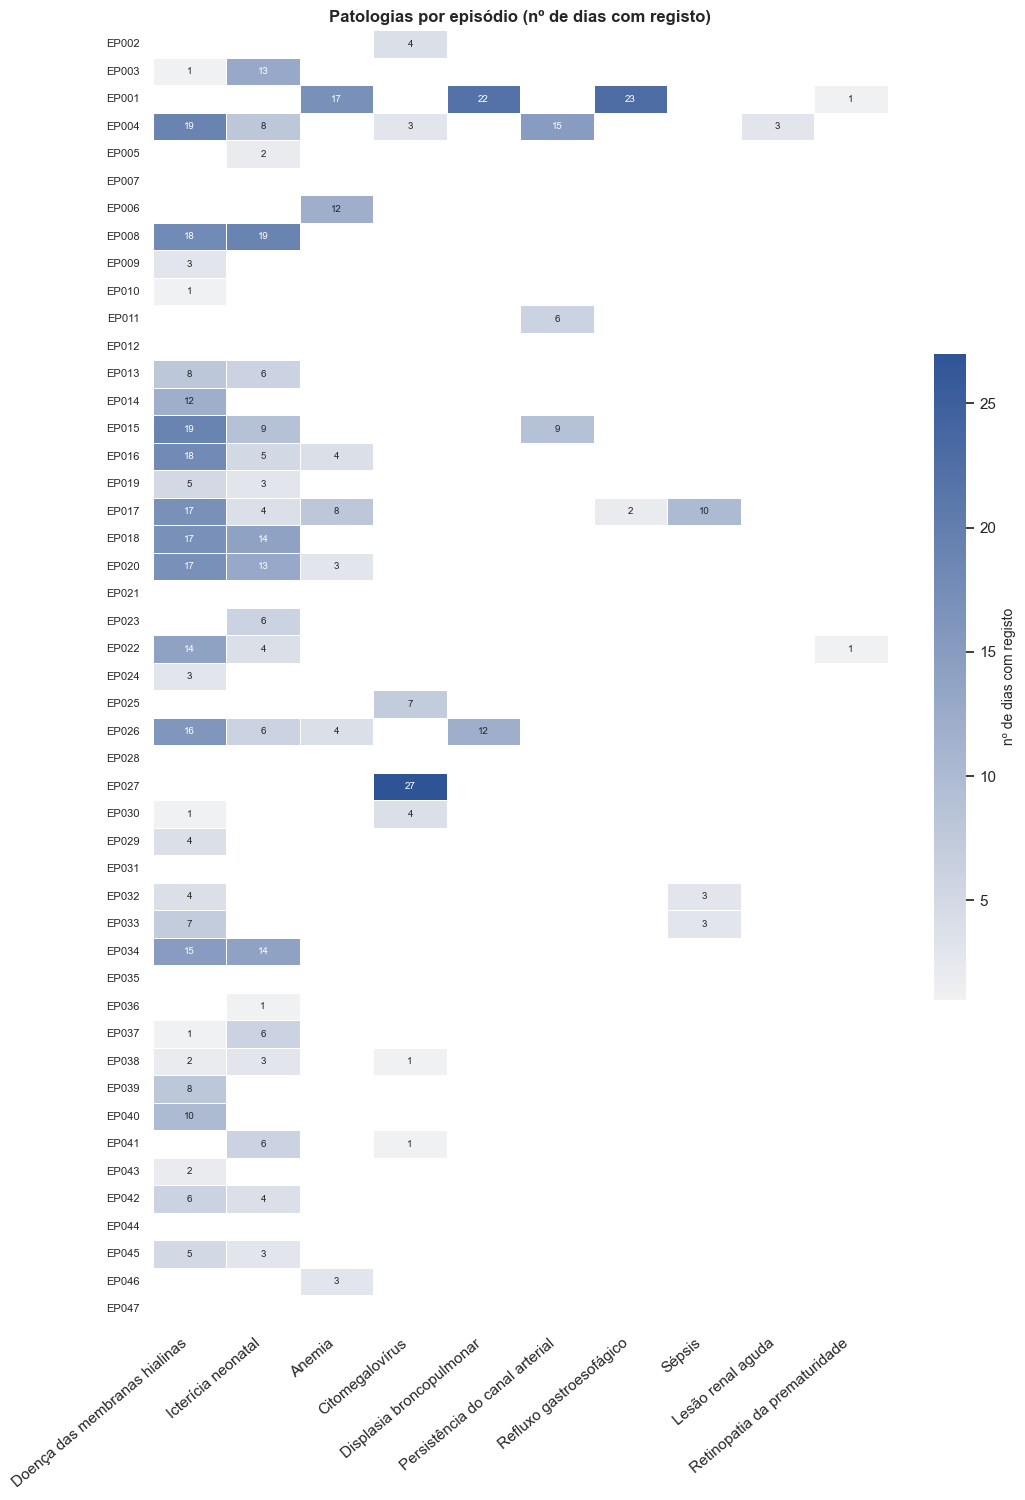

Episódios sem nenhuma patologia (nome oficial): 8 -> ['EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047']

Nº de patologias distintas por episódio:


,0,1,2,3,4,5
nº de episódios,8,17,13,5,2,2


Nº de episódios com cada patologia:


patologia,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Displasia broncopulmonar,Persistência do canal arterial,Refluxo gastroesofágico,Sépsis,Lesão renal aguda,Retinopatia da prematuridade
nº de episódios,28,21,7,7,2,3,2,3,1,2


In [24]:
# =============================================================================
# 2.3.7 Patologias por episódio
# Pergunta: que patologias tem cada episódio e em quantos dias são registadas?
# Mapa com uma linha por episódio (mesma ordem da linha temporal da 2.3.3) e
# uma coluna por patologia; cada célula mostra o nº de dias com registo.
# Para a vista não ficar dividida em variantes do mesmo nome, usa só os
# registos com código no formato EPnnn, data válida e nome oficial exato
# (os restantes são contados). Os dados não são alterados.
# =============================================================================
cod_ok_p = df_patologias["episodio"].str.fullmatch(r"EP\d{3}")
datas_p = pd.to_datetime(df_patologias["data"], format="%Y-%m-%d", errors="coerce")
oficial = df_patologias["patologia"].isin(OFICIAIS)
sel = cod_ok_p & datas_p.notna() & oficial
print(f"Registos usados: {sel.sum()} de {len(df_patologias)} "
      f"({(~sel).sum()} com código fora do formato, data inválida ou nome não oficial)")

pp = (pd.DataFrame({"episodio": df_patologias["episodio"], "data": datas_p,
                    "patologia": df_patologias["patologia"]})[sel]
        .drop_duplicates())

mapa = pp.groupby(["episodio", "patologia"])["data"].nunique().unstack(fill_value=0)
mapa = mapa[mapa.sum().sort_values(ascending=False).index]          # patologias mais frequentes primeiro
mapa = mapa.reindex(ordem, fill_value=0)                             # todos os episódios, pela ordem da 2.3.3

fig, ax = plt.subplots(figsize=(11, 0.28 * len(mapa) + 2))
sns.heatmap(mapa, mask=mapa == 0, annot=True, fmt="d", annot_kws={"size": 7},
            cmap=sns.light_palette(AZUL, as_cmap=True), linewidths=0.5, linecolor="white",
            cbar_kws={"label": "nº de dias com registo", "shrink": 0.5}, ax=ax)
ax.set_facecolor("white")
ax.grid(False)
ax.set_title("Patologias por episódio (nº de dias com registo)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

n_pat = (mapa > 0).sum(axis=1)
print(f"Episódios sem nenhuma patologia (nome oficial): {(n_pat == 0).sum()} -> {list(n_pat[n_pat == 0].index)}")
print("\nNº de patologias distintas por episódio:")
display(n_pat.value_counts().sort_index().to_frame("nº de episódios").T)
print("Nº de episódios com cada patologia:")
display((mapa > 0).sum().to_frame("nº de episódios").T)

Nº de patologias distintas por episódio-dia (nomes oficiais):


,1,2,3,4
nº de episódio-dia,267,121,31,2


Episódio-dia com 2 ou mais patologias: 154 de 421 (36.6%)


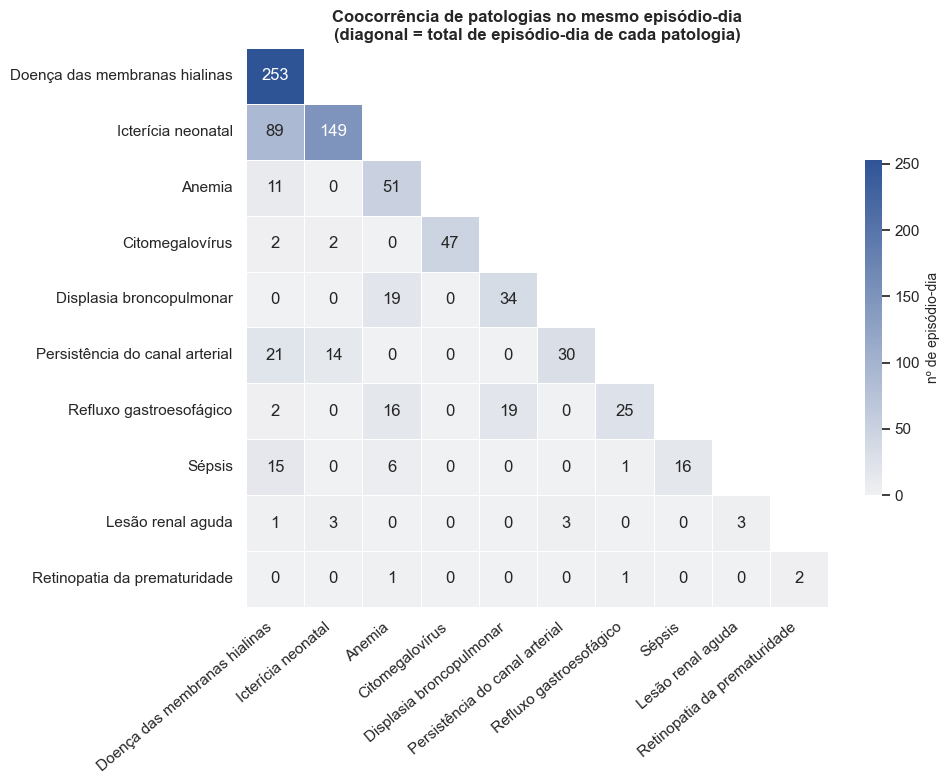

Pares de patologias mais frequentes no mesmo episódio-dia:


,patologia A,patologia B,episódio-dia em comum,% dos dias de A,% dos dias de B
0,Doença das membranas hialinas,Icterícia neonatal,89,35.2,59.7
1,Doença das membranas hialinas,Persistência do canal arterial,21,8.3,70.0
2,Displasia broncopulmonar,Refluxo gastroesofágico,19,55.9,76.0
3,Anemia,Displasia broncopulmonar,19,37.3,55.9
4,Anemia,Refluxo gastroesofágico,16,31.4,64.0
5,Doença das membranas hialinas,Sépsis,15,5.9,93.8
6,Icterícia neonatal,Persistência do canal arterial,14,9.4,46.7
7,Doença das membranas hialinas,Anemia,11,4.3,21.6
8,Anemia,Sépsis,6,11.8,37.5
9,Icterícia neonatal,Lesão renal aguda,3,2.0,100.0


In [25]:
# =============================================================================
# 2.3.8 Coocorrência de patologias no mesmo dia
# Pergunta: que patologias aparecem registadas no mesmo episódio e no mesmo dia?
# Usa a seleção pp da 2.3.7 (código no formato EPnnn, data válida e nome
# oficial, sem linhas repetidas).
# - Nº de patologias distintas por episódio-dia (com nomes oficiais)
# - Mapa: nº de episódio-dia em que cada par de patologias aparece em
#   simultâneo; a diagonal é o nº total de episódio-dia de cada patologia
# - Tabela com os pares mais frequentes e a percentagem que representam
# Os dados não são alterados.
# =============================================================================
dia_pat = pd.crosstab([pp["episodio"], pp["data"]], pp["patologia"]).clip(upper=1)
dia_pat = dia_pat[mapa.columns]                                      # mesma ordem da 2.3.7

n_por_dia = dia_pat.sum(axis=1)
print("Nº de patologias distintas por episódio-dia (nomes oficiais):")
display(n_por_dia.value_counts().sort_index().to_frame("nº de episódio-dia").T)
print(f"Episódio-dia com 2 ou mais patologias: {(n_por_dia >= 2).sum()} de {len(n_por_dia)} "
      f"({(n_por_dia >= 2).mean():.1%})")

co = dia_pat.T @ dia_pat
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co, mask=np.triu(np.ones_like(co, dtype=bool), k=1), annot=True, fmt="d",
            cmap=sns.light_palette(AZUL, as_cmap=True), linewidths=0.5, linecolor="white",
            cbar_kws={"label": "nº de episódio-dia", "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.set_title("Coocorrência de patologias no mesmo episódio-dia\n(diagonal = total de episódio-dia de cada patologia)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

total = pd.Series(np.diag(co), index=co.index)
pares = [(a, b, co.loc[a, b]) for i_a, a in enumerate(co.index) for b in co.columns[i_a + 1:] if co.loc[a, b] > 0]
tabela_pares = pd.DataFrame(pares, columns=["patologia A", "patologia B", "episódio-dia em comum"])
tabela_pares["% dos dias de A"] = (tabela_pares["episódio-dia em comum"] / tabela_pares["patologia A"].map(total) * 100).round(1)
tabela_pares["% dos dias de B"] = (tabela_pares["episódio-dia em comum"] / tabela_pares["patologia B"].map(total) * 100).round(1)
print("Pares de patologias mais frequentes no mesmo episódio-dia:")
display(tabela_pares.sort_values("episódio-dia em comum", ascending=False).head(10).reset_index(drop=True))

### Relatório de Exploração dos Dados

**Nota sobre os dados usados**

Todos os resultados desta tarefa foram obtidos com os dados tal como foram fornecidos, **sem qualquer correção**. Quando uma análise exigia um identificador fiável, os registos inválidos foram **excluídos apenas dessa análise** (não foram apagados nem alterados) e o número de registos excluídos foi sempre indicado:

- nas análises por episódio e por dia (2.3.3 e 2.3.4) usaram-se apenas registos com código de episódio no formato EPnnn e data válida (9 827 de 9 857 registos de sinais vitais; 30 excluídos);
- na análise dos sinais vitais por episódio (2.3.6) usaram-se apenas registos com código no formato EPnnn; os valores não numéricos (por exemplo, decimais com vírgula) ficaram em falta na cópia numérica temporária;
- nas análises das patologias (2.3.7 e 2.3.8) usaram-se apenas registos com código no formato EPnnn, data válida e nome de patologia oficial escrito exatamente (625 de 696 registos; 71 excluídos por terem código fora do formato, data inválida, nome não oficial ou patologia em falta), e as linhas repetidas foram contadas uma só vez.

Os registos excluídos representam uma pequena parte dos dados, pelo que as conclusões gerais não deverão mudar. Alguns valores, como a percentagem de episódio-dia com várias patologias, poderão ser revistos depois da correção dos dados na Fase 3; a tarefa 2.4 mede a dimensão de cada problema.

**Granularidade das tabelas**

Na tabela de sinais vitais existem 60 linhas totalmente repetidas, que correspondem a todas as combinações episódio + data + hora repetidas: as repetições são duplicados exatos, sem valores contraditórios. Dos 478 pares (código de episódio, data), 291 (61 %) têm exatamente 24 registos horários e 44 têm mais de 24 por causa dos duplicados; os restantes são dias parciais (início ou fim de episódio) ou pares isolados criados por gralhas no código ou na data. Na tabela de patologias existem 15 linhas totalmente repetidas, e 186 dos 458 pares (41 %) têm duas ou mais linhas no mesmo dia. Este valor é um limite superior, por incluir duplicados, variantes do mesmo nome e linhas sem patologia.

**Duração da monitorização por episódio (atributo-chave para a regressão)**

Existem 47 episódios com código no formato EPnnn. O número de dias com sinais vitais por episódio tem mediana de 7 dias, média de 9,6 dias, mínimo de 1 e máximo de 36 (EP026), com distribuição assimétrica à direita: cerca de 40 % dos episódios têm 5 dias ou menos. A monitorização é contínua em 44 episódios; só o EP004 (3 dias), o EP006 (3) e o EP007 (1) têm dias sem registos, todos no início de fevereiro, período em que existem várias datas inválidas, pelo que estas falhas podem resultar de datas mal escritas. Treze episódios começam no primeiro ou terminam no último dia do período dos dados e podem estar incompletos. Há pares de episódios com exatamente o mesmo período (EP015 e EP016, EP017 e EP018, EP039 e EP040, EP044 e EP045), que podem corresponder a gémeos ou a registos duplicados do mesmo bebé com códigos diferentes.

**Sinais vitais ao longo do dia**

A saturação não varia ao longo do dia (a mediana varia 0,75 % entre horas, face a um intervalo Q1–Q3 médio de 2,98 %). O pulso e a perfusão mostram um padrão fraco (pico de pulso por volta das 6h; perfusão mais alta de madrugada), mas com diferenças entre horas bem menores do que a variação normal em cada hora (6,0 vs. 19,1 bpm e 0,22 vs. 0,52 %).

**Relação entre os sinais vitais**

As correlações de Spearman entre os três sinais vitais são fracas: −0,20 entre saturação e pulso, −0,19 entre saturação e perfusão e 0,01 entre pulso e perfusão. Cada sinal vital traz informação própria; a relação negativa entre saturação e pulso é fisiologicamente plausível.

**Sinais vitais por episódio**

Ao contrário da hora do dia, o episódio tem grande influência nos sinais vitais:

| Sinal vital | Mediana global | Q1–Q3 global | Medianas dos episódios | Amplitude das medianas |
|---|---|---|---|---|
| Saturação (%) | 96,27 | 94,66 – 97,63 | 94,02 – 99,79 | 5,77 |
| Pulso (bpm) | 149,38 | 138,94 – 158,18 | 120,14 – 162,90 | 42,77 |
| Perfusão (%) | 1,15 | 0,91 – 1,44 | 0,70 – 1,64 | 0,94 |

Em todos os sinais vitais, a distância entre a menor e a maior mediana de um episódio é cerca do dobro da largura do intervalo Q1–Q3 global (5,77 vs. 2,97 na saturação, 42,77 vs. 19,24 no pulso e 0,94 vs. 0,53 na perfusão). Vários episódios têm a caixa quase toda de um dos lados da mediana global, por exemplo:

- saturação muito alta no EP041 e no EP046;
- pulso baixo no EP010 e no EP029, e alto no EP003, no EP027 e no EP045;
- perfusão baixa no EP021 e no EP032, e alta no EP031.

A variabilidade dentro de cada episódio também é diferente: há episódios muito estáveis (perfusão do EP030) e outros muito variáveis (perfusão do EP043). Cada bebé parece ter o seu próprio nível de referência. Por isso, o mesmo valor pode ser normal num episódio e invulgar noutro.

**Patologias por episódio**

Oito episódios não têm nenhuma patologia registada com nome oficial: EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047. Estes são os mesmos episódios que não têm patologia em nenhuma forma, pelo que a exclusão das variantes não esconde patologias de nenhum episódio. Dos restantes episódios:

- 17 têm uma só patologia, 13 têm duas, 5 têm três, 2 têm quatro e 2 têm cinco (EP004 e EP017);
- a doença das membranas hialinas (28 episódios) e a icterícia neonatal (21) são as mais comuns;
- a anemia e o citomegalovírus aparecem em 7 episódios cada; as restantes patologias aparecem em 1 a 3 episódios.

As patologias raras concentram-se em muito poucos episódios. A displasia broncopulmonar só aparece no EP001 e no EP026, e o refluxo gastroesofágico no EP001 e no EP017. O citomegalovírus é registado em 27 dias no EP027. Algumas patologias são registadas durante muitos dias seguidos no mesmo episódio (por exemplo, 22 a 23 dias no EP001) e outras em apenas 1 a 3 dias.

**Coocorrência de patologias**

Dos 421 episódio-dia com patologia (nome oficial), 267 têm uma só patologia, 121 têm duas, 31 têm três e 2 têm quatro. Assim, 154 episódio-dia (36,6 %) têm duas ou mais patologias em simultâneo. Este valor é um limite inferior, porque as variantes de nomes excluídas podem corresponder a uma segunda patologia no mesmo dia. Os pares mais frequentes são:

| Par de patologias | Episódio-dia em comum | % dos dias de cada uma |
|---|---|---|
| Membranas hialinas + icterícia neonatal | 89 | 35 % e 60 % |
| Membranas hialinas + persistência do canal arterial | 21 | 8 % e 70 % |
| Displasia broncopulmonar + refluxo gastroesofágico | 19 | 56 % e 76 % |
| Anemia + displasia broncopulmonar | 19 | 37 % e 56 % |
| Anemia + refluxo gastroesofágico | 16 | 31 % e 64 % |
| Membranas hialinas + sépsis | 15 | 6 % e 94 % |

Os três últimos pares de patologias raras resultam sobretudo de poucos episódios (como o EP001), pelo que refletem episódios concretos mais do que uma associação geral. A sépsis aparece quase sempre (94 % dos dias) com a doença das membranas hialinas. A lesão renal aguda aparece sempre com a icterícia neonatal, mas em apenas 3 dias. O citomegalovírus aparece quase sempre sozinho.

**Relação entre sinais vitais e patologias**

A relação entre os sinais vitais e as patologias exige a integração das duas tabelas e será analisada na Fase 3, depois da correção dos códigos de episódio, das datas e dos nomes das patologias.

**Hipóteses e impacto no resto do projeto**

| # | Hipótese / resultado | Impacto |
|---|---|---|
| H1 | Os duplicados são exatos e não contraditórios | Podem ser removidos na Fase 3 sem perda de informação |
| H2 | Pelo menos 36,6 % dos episódio-dia com patologia têm várias em simultâneo | A classificação (DM1) deverá ser tratada como um problema multi-label |
| H3 | A duração da monitorização é assimétrica (muitos episódios curtos, poucos longos) e 13 episódios podem estar incompletos | Considerar transformações da variável alvo e o tratamento dos episódios incompletos na regressão (DM2) |
| H4 | As falhas de dias no EP004, EP006 e EP007 podem resultar de datas mal escritas | Verificar na tarefa 2.4 e, se confirmado, recuperar as datas na Fase 3 |
| H5 | Há pares de episódios com o mesmo período | Verificar na tarefa 2.4 se os registos são duplicados ou de bebés distintos |
| H6 | A hora do dia tem pouca influência nos sinais vitais | A agregação dos sinais vitais por dia não deverá esconder padrões diários relevantes |
| H7 | Os três sinais vitais são pouco correlacionados entre si | Manter os três como variáveis de entrada dos modelos |
| H8 | Cada episódio tem o seu próprio nível de sinais vitais (as medianas dos episódios variam o dobro do intervalo Q1–Q3 global) | Criar na Fase 3 variáveis relativas ao próprio episódio (por exemplo, desvio em relação à mediana do episódio). Dividir treino e teste por episódio, para o modelo não aprender o bebé em vez da patologia |
| H9 | As patologias raras concentram-se em 1 a 3 episódios e 3 patologias oficiais não aparecem nos dados | Pouca capacidade de generalização para essas classes; ponderar agrupá-las ou excluí-las da classificação |
| H10 | 8 episódios não têm nenhuma patologia registada | Confirmar se a ausência de registo significa "sem patologia" antes de usar estes episódios na classificação |

## 2.4 Verificação da Qualidade dos Dados (Verify Data Quality)
> **CRISP-DM:** examinar a qualidade dos dados, respondendo a questões como: os dados estão completos (cobrem todos os casos necessários)? Estão corretos ou contêm erros e, se contêm, quão frequentes são? Existem valores em falta e, se sim, como estão representados, onde ocorrem e quão frequentes são? Output: *Data Quality Report*, com os resultados da verificação da qualidade e, quando existem problemas, as possíveis soluções.
>
> **Passos EDA:** 3 – Valores em falta; 7 – Outliers e valores anómalos.

Nesta secção os problemas de qualidade são medidos, mas não corrigidos: os dados não são alterados. Quando é preciso normalizar códigos de episódio, datas ou nomes de patologias para saber a que valor correto corresponde um valor errado, isso é feito apenas numa cópia temporária. As correções propostas no relatório são aplicadas na Fase 3 (Data Preparation).

,tabela,variável,em falta (NaN),texto vazio,% dos registos
0,sinais vitais,episodio,0,0,0.00
1,sinais vitais,data,0,0,0.00
2,sinais vitais,hora,0,0,0.00
3,sinais vitais,sat_o2,44,0,0.45
4,sinais vitais,puls_rate,64,0,0.65
5,sinais vitais,perfusion,42,0,0.43
6,patologias,episodio,0,0,0.00
7,patologias,data,0,0,0.00
8,patologias,patologia,12,0,1.72


Nº de sinais vitais em falta por registo:


sinais em falta,0,1,2
nº de registos,9708,148,1


Registos com 2 ou mais sinais vitais em falta:


,episodio,data,hora,sat_o2,puls_rate,perfusion
764,EP004,2024-02-07,12,NaN,NaN,0.79


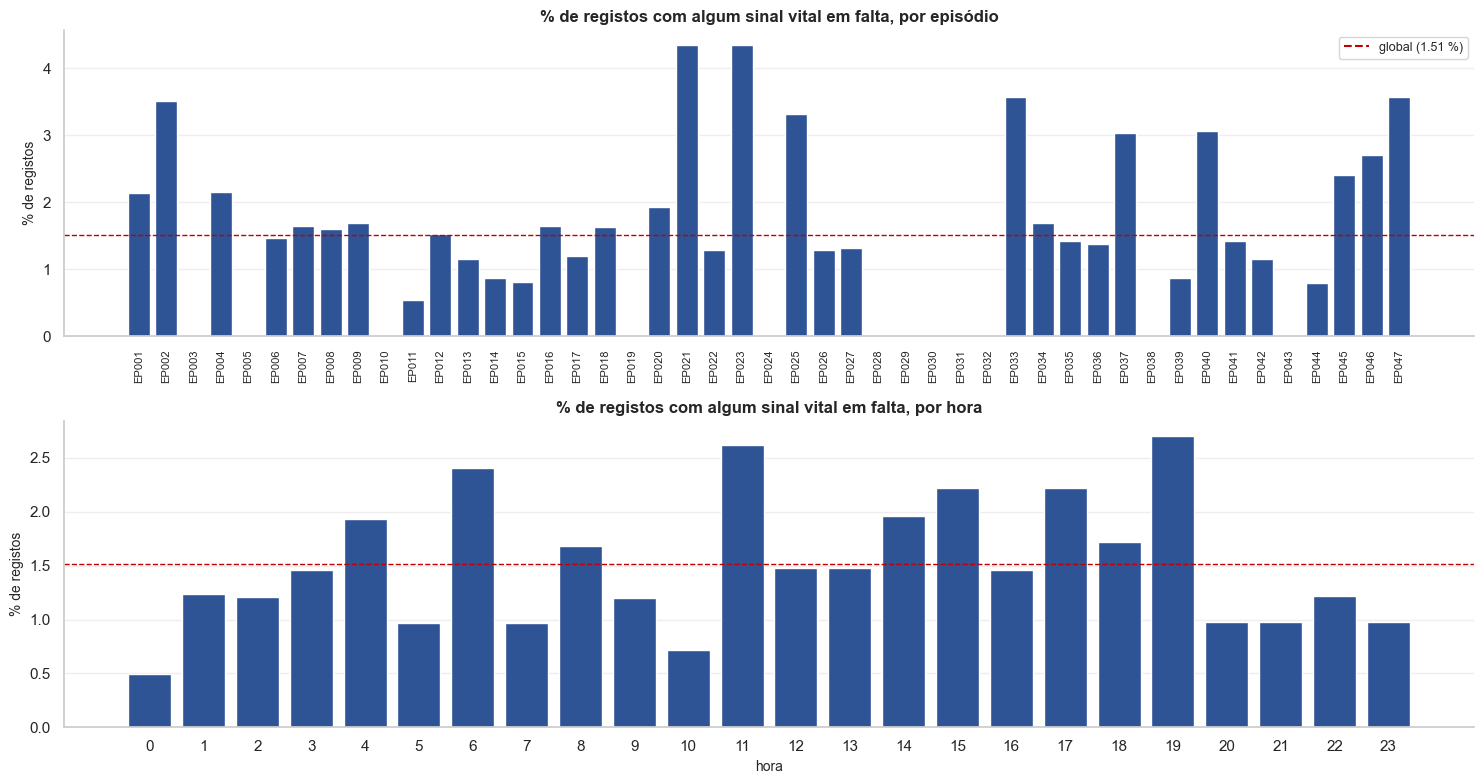

Episódios sem nenhum valor em falta: 12 de 47
Episódios com mais valores em falta:
episodio
EP023    4.35
EP021    4.35
EP047    3.57
EP033    3.57
EP002    3.51

Linhas sem patologia: 12


,episodio,data,patologia,tem outra patologia nesse dia
24,EP002,2024-02-04,NaN,não
38,EP008,2024-02-05,NaN,sim
167,EP001,2024-02-19,NaN,sim
177,EP001,2024-02-20,NaN,sim
220,EP001,2024-02-26,NaN,sim
254,EP019,2024-02-28,NaN,não
276,EP018,2024-03-01,NaN,sim
384,EP016,2024-03-13,NaN,sim
389,EP018,2024-03-13,NaN,sim
462,EP025,2024-03-20,NaN,não


Têm outra patologia registada no mesmo episódio-dia: 8 de 12


In [26]:
# =============================================================================
# 2.4.1 Valores em falta
# Mede os valores em falta em cada variável das duas tabelas e procura
# valores em falta "escondidos" (texto vazio ou só com espaços).
# Depois vê como se distribuem os que existem:
# - nos sinais vitais: quantos faltam no mesmo registo, por episódio e por hora
# - nas patologias: que linhas são e se esse episódio-dia tem outra patologia
# Nas vistas por episódio e por hora usam-se só códigos no formato EPnnn e
# horas de 0 a 23 (os restantes são tratados nas 2.4.3 e 2.4.5).
# Os dados não são alterados.
# =============================================================================

# --- 1) Valores em falta por variável
linhas = []
for nome, df in [("sinais vitais", df_sinais), ("patologias", df_patologias)]:
    for col in df.columns:
        em_falta = df[col].isna().sum()
        vazios = df[col].astype("string").str.strip().eq("").sum()
        linhas.append({"tabela": nome, "variável": col, "em falta (NaN)": em_falta,
                       "texto vazio": vazios,
                       "% dos registos": round((em_falta + vazios) / len(df) * 100, 2)})
display(pd.DataFrame(linhas))

# --- 2) Sinais vitais: quantos faltam no mesmo registo
falta_vit = df_sinais[VITAIS].isna()
n_falta = falta_vit.sum(axis=1)
print("Nº de sinais vitais em falta por registo:")
display(n_falta.value_counts().sort_index().rename_axis("sinais em falta").to_frame("nº de registos").T)
if (n_falta >= 2).any():
    print("Registos com 2 ou mais sinais vitais em falta:")
    display(df_sinais[n_falta >= 2])

# --- 3) Sinais vitais: % de registos com algum valor em falta, por episódio e por hora
algum = n_falta > 0
cod_ok_s = df_sinais["episodio"].str.fullmatch(r"EP\d{3}")
hora_num = pd.to_numeric(df_sinais["hora"], errors="coerce")
hora_ok = hora_num.between(0, 23)

por_ep = algum[cod_ok_s].groupby(df_sinais.loc[cod_ok_s, "episodio"]).mean() * 100
por_hora = algum[hora_ok].groupby(hora_num[hora_ok].astype(int)).mean() * 100
global_pct = algum.mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(15, 8))
axes[0].bar(por_ep.index, por_ep.values, color=AZUL)
axes[0].set_title("% de registos com algum sinal vital em falta, por episódio")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)
axes[1].bar(por_hora.index, por_hora.values, color=AZUL)
axes[1].set_title("% de registos com algum sinal vital em falta, por hora")
axes[1].set_xticks(range(24))
axes[1].set_xlabel("hora")
for ax in axes:
    ax.axhline(global_pct, color=VERMELHO, ls="--", lw=1)
    ax.set_ylabel("% de registos")
    ax.grid(axis="x", visible=False)
axes[0].legend(handles=[Line2D([], [], color=VERMELHO, ls="--", label=f"global ({global_pct:.2f} %)")],
               loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Episódios sem nenhum valor em falta: {(por_ep == 0).sum()} de {len(por_ep)}")
print(f"Episódios com mais valores em falta:\n{por_ep.sort_values(ascending=False).head(5).round(2).to_string()}")

# --- 4) Patologias: linhas sem patologia e se o mesmo episódio-dia tem outra patologia
sem = df_patologias["patologia"].isna() | df_patologias["patologia"].astype("string").str.strip().eq("")
linhas_sem = df_patologias[sem]
com = df_patologias.loc[~sem, ["episodio", "data"]].drop_duplicates()
outra = linhas_sem.merge(com, on=["episodio", "data"], how="left", indicator=True)["_merge"].eq("both").values
print(f"\nLinhas sem patologia: {len(linhas_sem)}")
display(linhas_sem.assign(**{"tem outra patologia nesse dia": np.where(outra, "sim", "não")}))
print(f"Têm outra patologia registada no mesmo episódio-dia: {outra.sum()} de {len(linhas_sem)}")

=== Sinais vitais ===
Linhas totalmente repetidas: 60 (0.61% dos registos)
Linhas com a chave repetida: 60
Repetições com valores diferentes (contraditórias): 0
Episódio-dia com cópias: 57 | episódios: 31


,episodio,data,nº de cópias
0,EP012,2024-02-19,2
1,EP016,2024-03-06,2
2,EP036,2024-04-19,2
3,EP001,2024-02-12,1
4,EP003,2024-01-31,1
5,EP004,2024-02-09,1
6,EP004,2024-02-10,1
7,EP003,2024-02-04,1
8,EP004,2024-02-08,1
9,EP008,2024-02-06,1


Distância (nº de linhas) entre a cópia e a linha original:


,min,50%,max
linhas,1.0,1.0,1.0


Cópias logo a seguir à original: 60 de 60

=== Patologias ===
Linhas totalmente repetidas: 15 (2.16% dos registos)
Linhas com a chave repetida: 15
Repetições com valores diferentes (contraditórias): 0
Episódio-dia com cópias: 15 | episódios: 13


,episodio,data,nº de cópias
0,EP001,2024-02-15,1
1,EP003,2024-01-30,1
2,EP003,2024-02-10,1
3,EP004,2024-02-17,1
4,EP010,2024-02-11,1
5,EP014,2024-03-02,1
6,EP015,2024-02-26,1
7,EP015,2024-03-01,1
8,EP018,2024-03-02,1
9,EP019,2024-03-03,1


Distância (nº de linhas) entre a cópia e a linha original:


,min,50%,max
linhas,1.0,1.0,1.0


Cópias logo a seguir à original: 15 de 15



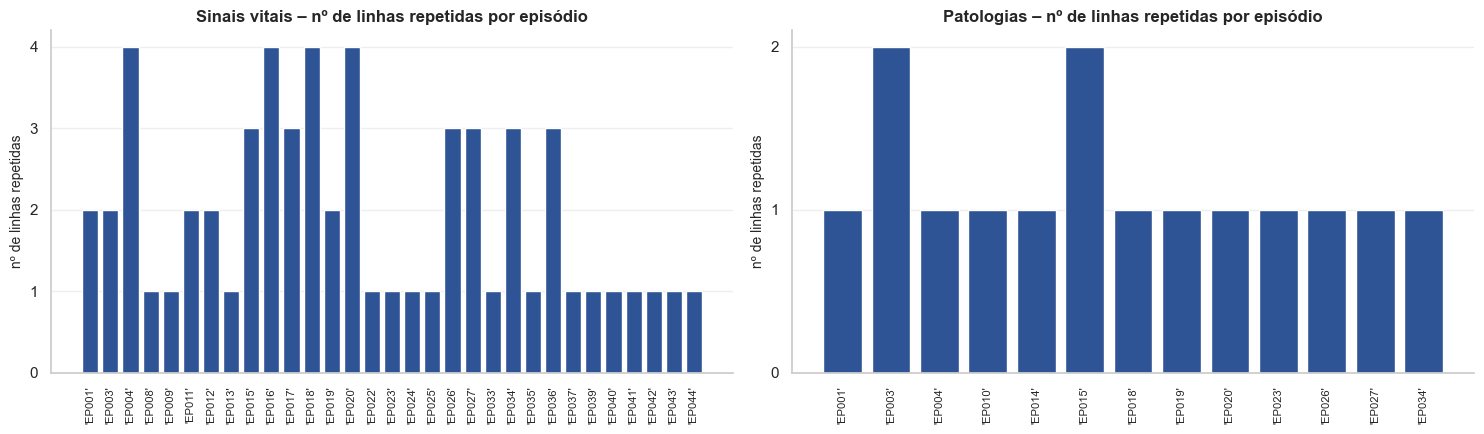

In [27]:
# =============================================================================
# 2.4.2 Registos duplicados
# Na 2.3.1 e na 2.3.2 já contámos as linhas repetidas. Aqui verifica-se:
# 1) se há registos com a mesma chave mas valores diferentes (contraditórios)
# 2) em que episódios e dias estão as repetições
# 3) a que distância no ficheiro está cada cópia da linha original
#    (cópia logo a seguir = erro pontual; bloco inteiro repetido = erro de
#    exportação ou junção de ficheiros)
# Chave dos sinais vitais: episodio + data + hora
# Chave das patologias:    episodio + data + patologia (todas as colunas)
# Os códigos e as datas são usados tal como estão escritos.
# Os dados não são alterados.
# =============================================================================
tabelas = [("Sinais vitais", df_sinais, ["episodio", "data", "hora"]),
           ("Patologias", df_patologias, ["episodio", "data", "patologia"])]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for k, (nome, df, chave) in enumerate(tabelas):
    exatos = df.duplicated(keep="first")                 # cópias de uma linha anterior igual
    por_chave = df.duplicated(subset=chave, keep="first")
    contraditorios = por_chave & ~exatos                 # mesma chave, valores diferentes
    print(f"=== {nome} ===")
    print(f"Linhas totalmente repetidas: {exatos.sum()} ({exatos.mean():.2%} dos registos)")
    print(f"Linhas com a chave repetida: {por_chave.sum()}")
    print(f"Repetições com valores diferentes (contraditórias): {contraditorios.sum()}")

    # Onde estão: nº de cópias por episódio-dia
    copias = df[exatos]
    onde = copias.groupby(["episodio", "data"]).size().sort_values(ascending=False)
    print(f"Episódio-dia com cópias: {len(onde)} | episódios: {copias['episodio'].nunique()}")
    display(onde.rename("nº de cópias").reset_index().head(10))

    # Distância no ficheiro entre cada cópia e a primeira ocorrência
    pos = pd.Series(np.arange(len(df)), index=df.index)
    primeira = pos.groupby([df[c] for c in df.columns], dropna=False).transform("min")
    distancia = (pos - primeira)[exatos]
    print("Distância (nº de linhas) entre a cópia e a linha original:")
    display(distancia.describe()[["min", "50%", "max"]].to_frame("linhas").T)
    print(f"Cópias logo a seguir à original: {(distancia == 1).sum()} de {len(distancia)}\n")

    # Gráfico: nº de cópias por código de episódio (como está escrito)
    por_ep = copias["episodio"].value_counts().sort_index()
    axes[k].bar([repr(c) for c in por_ep.index], por_ep.values, color=AZUL)
    axes[k].set_title(f"{nome} – nº de linhas repetidas por episódio")
    axes[k].set_ylabel("nº de linhas repetidas")
    axes[k].tick_params(axis="x", rotation=90, labelsize=8)
    axes[k].yaxis.get_major_locator().set_params(integer=True)
    axes[k].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [28]:
# =============================================================================
# 2.4.3 Códigos de episódio fora do formato
# Para cada código fora do formato EPnnn, procura o código correto a que
# provavelmente corresponde, numa cópia temporária:
#   maiúsculas -> retirar espaços, hífenes, pontos, etc. -> "EP" + 3 dígitos
#   (ex.: " ep1" -> "EP001"; "EP 002" -> "EP002")
# Com esta normalização, só para medir, verifica-se:
# 1) que códigos errados existem, quantos registos têm e a que código levam
# 2) quantos episódios existem realmente e se aparecem nas duas tabelas
# 3) se os registos com código errado repetem registos que já existem com o
#    código correto (duplicados escondidos) ou se trazem informação nova
# Os dados não são alterados.
# =============================================================================
import re

def normalizar_codigo(codigo):
    """Devolve o código no formato EPnnn ou None se não for reconhecível."""
    limpo = re.sub(r"[^A-Z0-9]", "", str(codigo).upper())
    m = re.fullmatch(r"(?:EP|E|P)?(\d{1,3})", limpo)
    return f"EP{int(m.group(1)):03d}" if m else None

# --- 1) Códigos fora do formato e código normalizado
linhas = []
for nome, df in [("sinais vitais", df_sinais), ("patologias", df_patologias)]:
    errados = df.loc[~df["episodio"].str.fullmatch(r"EP\d{3}"), "episodio"].value_counts()
    for cod, n in errados.items():
        linhas.append({"tabela": nome, "código original": repr(cod), "nº de registos": n,
                       "código normalizado": normalizar_codigo(cod)})
tab_cod = pd.DataFrame(linhas)
validos = set(df_sinais["episodio"]) | set(df_patologias["episodio"])
tab_cod["corresponde a um código já existente"] = tab_cod["código normalizado"].isin(validos).map({True: "sim", False: "não"})
display(tab_cod)
print(f"Códigos não reconhecidos pela normalização: {tab_cod['código normalizado'].isna().sum()}")

# --- 2) Nº real de episódios depois de normalizar
ep_s = set(df_sinais["episodio"].map(normalizar_codigo).dropna())
ep_p = set(df_patologias["episodio"].map(normalizar_codigo).dropna())
print(f"\nEpisódios distintos depois de normalizar: sinais vitais {len(ep_s)} | "
      f"patologias {len(ep_p)} | total {len(ep_s | ep_p)}")
print(f"Só nos sinais vitais: {sorted(ep_s - ep_p)}")
print(f"Só nas patologias:   {sorted(ep_p - ep_s)}")

# --- 3) Os registos com código errado repetem registos existentes?
def comparar(df, chave):
    ok = df["episodio"].str.fullmatch(r"EP\d{3}")
    errados = df[~ok].assign(episodio=df.loc[~ok, "episodio"].map(normalizar_codigo))
    certos = df[ok]
    chave_igual = errados.merge(certos[chave].drop_duplicates(), on=chave, how="left", indicator=True)["_merge"].eq("both")
    tudo_igual = errados.merge(certos.drop_duplicates(), on=list(df.columns), how="left", indicator=True)["_merge"].eq("both")
    return pd.Series({"registos com código errado": len(errados),
                      "chave já existe com o código certo": chave_igual.sum(),
                      "… e com valores iguais (duplicado escondido)": tudo_igual.sum(),
                      "chave nova (informação nova)": (~chave_igual).sum()})

display(pd.DataFrame({"sinais vitais": comparar(df_sinais, ["episodio", "data", "hora"]),
                      "patologias": comparar(df_patologias, ["episodio", "data", "patologia"])}))

,tabela,código original,nº de registos,código normalizado,corresponde a um código já existente
0,sinais vitais,'ep018',2,EP018,sim
1,sinais vitais,' EP011',1,EP011,sim
2,sinais vitais,'EP 016',1,EP016,sim
3,sinais vitais,'ep019',1,EP019,sim
4,sinais vitais,'ep016',1,EP016,sim
5,sinais vitais,' EP016',1,EP016,sim
6,sinais vitais,'ep023',1,EP023,sim
7,sinais vitais,' EP027',1,EP027,sim
8,sinais vitais,'EP 034',1,EP034,sim
9,sinais vitais,'EP 036',1,EP036,sim


Códigos não reconhecidos pela normalização: 0

Episódios distintos depois de normalizar: sinais vitais 47 | patologias 39 | total 47
Só nos sinais vitais: ['EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047']
Só nas patologias:   []


,sinais vitais,patologias
registos com código errado,12,6
chave já existe com o código certo,0,0
… e com valores iguais (duplicado escondido),0,0
chave nova (informação nova),12,6


In [29]:
# =============================================================================
# 2.4.4 Datas inválidas
# Para cada data que não está no formato AAAA-MM-DD ou que não existe no
# calendário, identifica o tipo de erro e tenta, numa cópia temporária,
# descobrir a data correta:
#   - DD/MM/AAAA                 -> reescrever como AAAA-MM-DD
#   - mês > 12 (ex.: 2024-13-02) -> dia e mês trocados (2024-02-13)
#   - dia que não existe no mês (ex.: 2024-02-31) -> não recuperável
# Depois, com o código de episódio normalizado (função da 2.4.3), verifica se
# cada registo recuperado:
#   - repete uma hora/patologia que já existe nesse dia (duplicado escondido)
#   - preenche uma hora em falta num dia que já tem registos
#   - preenche um dia sem registos dentro do episódio (falha de dias – H4)
#   - fica fora do período do episódio
# Os dados não são alterados.
# =============================================================================
def recuperar_data(texto):
    """Devolve (tipo de erro, data recuperada ou NaT)."""
    s = str(texto).strip()
    m = re.fullmatch(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    if m:
        d, mes, a = m.groups()
        tipo = "formato DD/MM/AAAA"
    else:
        m = re.fullmatch(r"(\d{4})-(\d{1,2})-(\d{1,2})", s)
        if not m:
            return "outro formato", pd.NaT
        a, mes, d = m.groups()
        if int(mes) > 12:
            tipo, d, mes = "mês > 12 (dia e mês trocados?)", mes, d
        else:
            tipo = "dia que não existe no mês"
    data = pd.to_datetime(f"{a}-{int(mes):02d}-{int(d):02d}", format="%Y-%m-%d", errors="coerce")
    return tipo, data

def analisar_datas(df, col_extra):
    """Classifica as datas inválidas de uma tabela e o que acontece se forem recuperadas."""
    datas = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")
    ep = df["episodio"].map(normalizar_codigo)
    validos = pd.DataFrame({"episodio": ep, "data": datas, col_extra: df[col_extra]})[datas.notna()]
    dias = set(zip(validos["episodio"], validos["data"]))
    chaves = set(zip(validos["episodio"], validos["data"], validos[col_extra]))
    limites = validos.groupby("episodio")["data"].agg(["min", "max"])

    linhas = []
    for i in df.index[datas.isna()]:
        tipo, rec = recuperar_data(df.at[i, "data"])
        e = ep[i]
        if pd.isna(rec):
            situacao = "não recuperável"
        elif (e, rec, df.at[i, col_extra]) in chaves:
            situacao = "repete um registo existente (duplicado escondido)"
        elif (e, rec) in dias:
            situacao = "preenche um registo em falta num dia com registos"
        elif limites.at[e, "min"] <= rec <= limites.at[e, "max"]:
            situacao = "preenche um dia sem registos (falha de dias)"
        else:
            situacao = "fora do período do episódio"
        linhas.append({"episódio": e, "data original": df.at[i, "data"], col_extra: df.at[i, col_extra],
                       "tipo de erro": tipo, "data recuperada": rec, "situação": situacao})
    return pd.DataFrame(linhas), validos

for nome, df, col in [("Sinais vitais", df_sinais, "hora"), ("Patologias", df_patologias, "patologia")]:
    tab, validos = analisar_datas(df, col)
    print(f"=== {nome}: {len(tab)} registos com data inválida ===")
    display(tab.sort_values(["episódio", "data recuperada"]).reset_index(drop=True))
    display(pd.crosstab(tab["tipo de erro"], tab["situação"], margins=True, margins_name="total"))

# --- Falhas de dias (H4): dias sem sinais vitais dentro de cada episódio e
#     datas inválidas que existem nesses episódios
tab_s, validos_s = analisar_datas(df_sinais, "hora")
print("=== Falhas de dias nos sinais vitais (H4) ===")
for e, g in validos_s.groupby("episodio"):
    todos = pd.date_range(g["data"].min(), g["data"].max())
    falta = todos.difference(g["data"].unique())
    if len(falta):
        inval = tab_s[tab_s["episódio"] == e]
        print(f"{e}: dias sem registos {[d.strftime('%d/%m') for d in falta]} | "
              f"datas inválidas neste episódio: {list(inval['data original'])} "
              f"-> recuperadas: {[d.strftime('%d/%m') if pd.notna(d) else '—' for d in inval['data recuperada']]}")

=== Sinais vitais: 18 registos com data inválida ===


,episódio,data original,hora,tipo de erro,data recuperada,situação
0,EP002,31/01/2024,19,formato DD/MM/AAAA,2024-01-31,preenche um registo em falta num dia com registos
1,EP006,10/02/2024,18,formato DD/MM/AAAA,2024-02-10,preenche um registo em falta num dia com registos
2,EP006,10/02/2024,22,formato DD/MM/AAAA,2024-02-10,preenche um registo em falta num dia com registos
3,EP008,05/02/2024,8,formato DD/MM/AAAA,2024-02-05,preenche um registo em falta num dia com registos
4,EP008,14/02/2024,0,formato DD/MM/AAAA,2024-02-14,preenche um registo em falta num dia com registos
5,EP016,09/03/2024,4,formato DD/MM/AAAA,2024-03-09,preenche um registo em falta num dia com registos
6,EP016,2024-02-31,9,dia que não existe no mês,NaT,não recuperável
7,EP018,2024-13-02,19,mês > 12 (dia e mês trocados?),2024-02-13,fora do período do episódio
8,EP018,18/03/2024,2,formato DD/MM/AAAA,2024-03-18,preenche um registo em falta num dia com registos
9,EP020,13/03/2024,18,formato DD/MM/AAAA,2024-03-13,preenche um registo em falta num dia com registos


situação,fora do período do episódio,não recuperável,preenche um registo em falta num dia com registos,total
tipo de erro,,,,
dia que não existe no mês,0,1,0,1
formato DD/MM/AAAA,0,0,15,15
mês > 12 (dia e mês trocados?),2,0,0,2
total,2,1,15,18


=== Patologias: 10 registos com data inválida ===


,episódio,data original,patologia,tipo de erro,data recuperada,situação
0,EP001,10/02/2024,Displasia broncopulmonar,formato DD/MM/AAAA,2024-02-10,preenche um registo em falta num dia com registos
1,EP015,26/02/2024,Doença das membranas hialinas,formato DD/MM/AAAA,2024-02-26,preenche um registo em falta num dia com registos
2,EP016,26/02/2024,Doenca das membranas hialinas,formato DD/MM/AAAA,2024-02-26,preenche um registo em falta num dia com registos
3,EP017,2024-13-02,Sépsis,mês > 12 (dia e mês trocados?),2024-02-13,fora do período do episódio
4,EP017,09/03/2024,Sépsis,formato DD/MM/AAAA,2024-03-09,preenche um registo em falta num dia com registos
5,EP022,20/03/2024,Icterícia neonatal,formato DD/MM/AAAA,2024-03-20,preenche um registo em falta num dia com registos
6,EP023,12/03/2024,Icterícia neonatal,formato DD/MM/AAAA,2024-03-12,preenche um dia sem registos (falha de dias)
7,EP025,2024-02-30,Citomegalovírus,dia que não existe no mês,NaT,não recuperável
8,EP042,20/04/2024,Doença das membranas hialinas,formato DD/MM/AAAA,2024-04-20,preenche um registo em falta num dia com registos
9,EP043,14/04/2024,Doença das membranas hialinas,formato DD/MM/AAAA,2024-04-14,preenche um dia sem registos (falha de dias)


situação,fora do período do episódio,não recuperável,preenche um dia sem registos (falha de dias),preenche um registo em falta num dia com registos,total
tipo de erro,,,,,
dia que não existe no mês,0,1,0,0,1
formato DD/MM/AAAA,0,0,2,6,8
mês > 12 (dia e mês trocados?),1,0,0,0,1
total,1,1,2,6,10


=== Falhas de dias nos sinais vitais (H4) ===
EP004: dias sem registos ['04/02', '05/02', '06/02'] | datas inválidas neste episódio: [] -> recuperadas: []
EP006: dias sem registos ['06/02', '07/02', '08/02'] | datas inválidas neste episódio: ['10/02/2024', '10/02/2024'] -> recuperadas: ['10/02', '10/02']
EP007: dias sem registos ['05/02'] | datas inválidas neste episódio: [] -> recuperadas: []


In [30]:
# =============================================================================
# 2.4.5 Horas fora do domínio (0–23)
# Para cada registo com hora fora de 0–23 (ex.: -1, 24, 25), verifica, com o
# código de episódio normalizado (2.4.3) e só com datas válidas:
# - que horas de 0–23 faltam nesse episódio-dia
# - se os valores dos sinais vitais repetem outra hora do mesmo dia
# - a "hora equivalente" se a hora tivesse passado para o dia seguinte ou
#   anterior (24 -> 0h do dia seguinte; 25 -> 1h do dia seguinte;
#   -1 -> 23h do dia anterior) e se essa hora está em falta
# Ajuda a decidir na Fase 3 se a hora é recuperável ou se o registo se descarta.
# Os dados não são alterados.
# =============================================================================
hora_num = pd.to_numeric(df_sinais["hora"], errors="coerce")
fora = ~hora_num.between(0, 23)
base = pd.DataFrame({"episodio": df_sinais["episodio"].map(normalizar_codigo),
                     "data": pd.to_datetime(df_sinais["data"], format="%Y-%m-%d", errors="coerce"),
                     "hora": hora_num})
dentro = base[~fora & base["data"].notna()]
horas_dia = dentro.groupby(["episodio", "data"])["hora"].agg(set)
limites = dentro.groupby("episodio")["data"].agg(["min", "max"])

linhas = []
for i in base.index[fora]:
    e, d, h = base.at[i, "episodio"], base.at[i, "data"], base.at[i, "hora"]
    presentes = horas_dia.get((e, d), set())
    em_falta = sorted(set(range(24)) - presentes)

    # valores iguais aos de outra hora do mesmo episódio-dia?
    mesmo_dia = dentro.index[(dentro["episodio"] == e) & (dentro["data"] == d)]
    repete = df_sinais.loc[mesmo_dia, VITAIS].eq(df_sinais.loc[i, VITAIS]).all(axis=1).any()

    # hora equivalente no dia seguinte/anterior
    if pd.isna(d):
        equiv_txt, equiv_falta = "—", "data inválida"
    else:
        equiv = d + pd.Timedelta(hours=h)
        e_dia, e_hora = equiv.normalize(), equiv.hour
        equiv_txt = f"{e_dia:%d/%m} {e_hora}h"
        if limites.at[e, "min"] <= e_dia <= limites.at[e, "max"]:
            equiv_falta = "sim" if e_hora not in horas_dia.get((e, e_dia), set()) else "não"
        else:
            equiv_falta = "fora do período do episódio"

    linhas.append({"episódio": e, "data": df_sinais.at[i, "data"], "hora": df_sinais.at[i, "hora"],
                   "registos nesse dia (0–23h)": len(presentes),
                   "horas em falta nesse dia": em_falta,
                   "repete valores de outra hora": "sim" if repete else "não",
                   "hora equivalente": equiv_txt,
                   "hora equivalente em falta": equiv_falta})

print(f"Registos com hora fora de 0–23: {fora.sum()}")
display(pd.DataFrame(linhas))

Registos com hora fora de 0–23: 8


,episódio,data,hora,registos nesse dia (0–23h),horas em falta nesse dia,repete valores de outra hora,hora equivalente,hora equivalente em falta
0,EP004,2024-02-11,-1,23,[17],não,10/02 23h,não
1,EP006,2024-02-14,24,23,[7],não,15/02 0h,não
2,EP004,2024-02-17,-1,23,[4],não,16/02 23h,não
3,EP023,2024-03-09,-1,6,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 21]",não,08/03 23h,fora do período do episódio
4,EP026,2024-03-29,-1,23,[5],não,28/03 23h,não
5,EP031,2024-03-29,24,14,"[13, 15, 16, 17, 18, 19, 20, 21, 22, 23]",não,30/03 0h,fora do período do episódio
6,EP026,2024-04-16,25,23,[0],não,17/04 1h,não
7,EP044,2024-04-20,-1,23,[4],não,19/04 23h,não


Nº de valores em cada categoria:


,sat_o2,puls_rate,perfusion
em falta,44,64,42
não numérico,3,7,5
fora do domínio,27,20,23
outlier (IQR) plausível,148,79,302
normal,9635,9687,9485


% de valores inutilizáveis (em falta + não numérico + fora do domínio): {'sat_o2': '0.75 %', 'puls_rate': '0.92 %', 'perfusion': '0.71 %'}
Não numéricos recuperáveis trocando ',' por '.': {'sat_o2': '3 de 3', 'puls_rate': '7 de 7', 'perfusion': '5 de 5'}

sat_o2 – fora do domínio (0, 100): 27 valores
   ligeiramente acima do limite (até +5 %): 9 valores, de 101.0 a 104.0
   restantes (valor: nº de registos): {-5.0: 4, -1.0: 2, 150.0: 2, 250.0: 8, 999.0: 2}
sat_o2 – valores não numéricos: ['97,57', '94,09', '95,6']

puls_rate – fora do domínio (40, 300): 20 valores
   restantes (valor: nº de registos): {-10.0: 5, 0.0: 5, 400.0: 3, 520.0: 3, 999.0: 4}
puls_rate – valores não numéricos: ['118,64', '114,84', '164,24', '162,53', '136,17', '158,65', '138,29']

perfusion – fora do domínio (0, 20): 23 valores
   restantes (valor: nº de registos): {-1.0: 7, -0.5: 2, 25.0: 5, 50.0: 4, 99.0: 5}
perfusion – valores não numéricos: ['1,92', '1,16', '1,63', '1,29', '1,43']

Registos com algum valor f

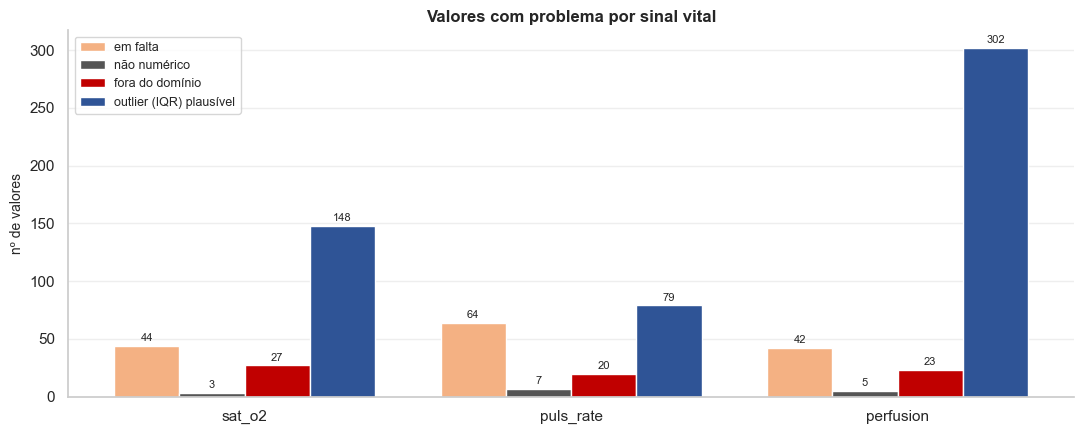

In [31]:
# =============================================================================
# 2.4.6 Sinais vitais: valores não numéricos, impossíveis e outliers
# Classifica cada valor de cada sinal vital numa de cinco categorias:
#   em falta | não numérico | fora do domínio | outlier (IQR) plausível | normal
# - Não numérico: texto que não é número (ex.: decimal com vírgula); testa-se,
#   numa cópia, se trocar "," por "." o torna recuperável
# - Fora do domínio: valor impossível (limites abaixo, definidos a partir da
#   literatura neonatal; ver relatório):
#     saturação: o oxímetro não mede acima de 100 %
#     pulso: fora de 40–300 bpm é incompatível com um recém-nascido vivo
#     perfusão: 0 = sem sinal de pulso (leitura em falta); acima de 20 % não
#     ocorre (P95 dos recém-nascidos saudáveis = 4,5 %)
# - Outlier (IQR): fora dos bigodes 1,5 × IQR da 2.2.7, mas dentro do domínio
# Usa a cópia numérica num da 2.2.6. Os dados não são alterados.
# =============================================================================
DOMINIO = {"sat_o2": (0, 100),      # % (0 excluído: sem leitura; 100 incluído)
           "puls_rate": (40, 300),  # bpm (40 e 300 incluídos)
           "perfusion": (0, 20)}    # % (0 excluído: sem sinal; 20 incluído)
EXCLUI_ZERO = {"sat_o2", "perfusion"}   # variáveis em que um 0 significa "sem leitura"

CATEGORIAS = ["em falta", "não numérico", "fora do domínio", "outlier (IQR) plausível", "normal"]
cat = pd.DataFrame(index=df_sinais.index, columns=VITAIS, dtype="object")
resumo, recuperaveis = {}, {}
for v in VITAIS:
    bruto, x = df_sinais[v], num[v]
    lo, hi = DOMINIO[v]
    abaixo = (x <= lo) if v in EXCLUI_ZERO else (x < lo)
    q1, q3 = x.quantile([0.25, 0.75])
    b_lo, b_hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

    cat[v] = np.select(
        [bruto.isna(), x.isna(), abaixo | (x > hi), (x < b_lo) | (x > b_hi)],
        CATEGORIAS[:4], default="normal")
    resumo[v] = cat[v].value_counts().reindex(CATEGORIAS, fill_value=0)

    nao_num = bruto[cat[v] == "não numérico"]
    recuperaveis[v] = pd.to_numeric(nao_num.str.replace(",", ".", regex=False), errors="coerce").notna().sum()

tab = pd.DataFrame(resumo)
print("Nº de valores em cada categoria:")
display(tab)
pct = tab.loc[["em falta", "não numérico", "fora do domínio"]].sum() / len(df_sinais) * 100
print("% de valores inutilizáveis (em falta + não numérico + fora do domínio):",
      {v: f"{pct[v]:.2f} %" for v in VITAIS})
print("Não numéricos recuperáveis trocando ',' por '.':",
      {v: f"{recuperaveis[v]} de {resumo[v]['não numérico']}" for v in VITAIS})

# --- Que valores são? (fora do domínio e não numéricos)
for v in VITAIS:
    fora_v = num.loc[cat[v] == "fora do domínio", v]
    lo, hi = DOMINIO[v]
    perto = fora_v[(fora_v > hi) & (fora_v <= hi * 1.05)]          # até 5 % acima do limite
    longe = fora_v.drop(perto.index)
    print(f"\n{v} – fora do domínio {DOMINIO[v]}: {len(fora_v)} valores")
    if len(perto):
        print(f"   ligeiramente acima do limite (até +5 %): {len(perto)} valores, de {perto.min()} a {perto.max()}")
    print(f"   restantes (valor: nº de registos): {longe.value_counts().sort_index().to_dict()}")
    print(f"{v} – valores não numéricos: {df_sinais.loc[cat[v] == 'não numérico', v].tolist()}")

# --- Onde estão os valores fora do domínio?
algum_fora = (cat == "fora do domínio").any(axis=1)
print(f"\nRegistos com algum valor fora do domínio: {algum_fora.sum()} | "
      f"episódios: {df_sinais.loc[algum_fora, 'episodio'].map(normalizar_codigo).nunique()} | "
      f"registos com mais de um: {((cat == 'fora do domínio').sum(axis=1) > 1).sum()}")

# --- Gráfico: nº de valores com problema por sinal vital e categoria
cores_cat = {"em falta": LARANJA, "não numérico": CINZA, "fora do domínio": VERMELHO,
             "outlier (IQR) plausível": AZUL}
fig, ax = plt.subplots(figsize=(11, 4.5))
largura = 0.2
for j, (c, cor) in enumerate(cores_cat.items()):
    pos = np.arange(len(VITAIS)) + (j - 1.5) * largura
    barras = ax.bar(pos, tab.loc[c, VITAIS].astype(int), width=largura, color=cor, label=c)
    ax.bar_label(barras, fontsize=8, padding=2)
ax.set_xticks(range(len(VITAIS)), VITAIS)
ax.set_ylabel("nº de valores")
ax.set_title("Valores com problema por sinal vital")
ax.legend(fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Intervalos de plausibilidade: {'sat_o2': (70, 100), 'puls_rate': (80, 220), 'perfusion': (0.2, 10)}


,dentro do domínio,suspeitos abaixo,suspeitos acima,% suspeitos,isolados,sustentados,sem vizinhos,com outro sinal suspeito na mesma hora
sat_o2,9697,0,0,0.0,0,0,0,0
puls_rate,9680,0,0,0.0,0,0,0,0
perfusion,9701,0,0,0.0,0,0,0,0


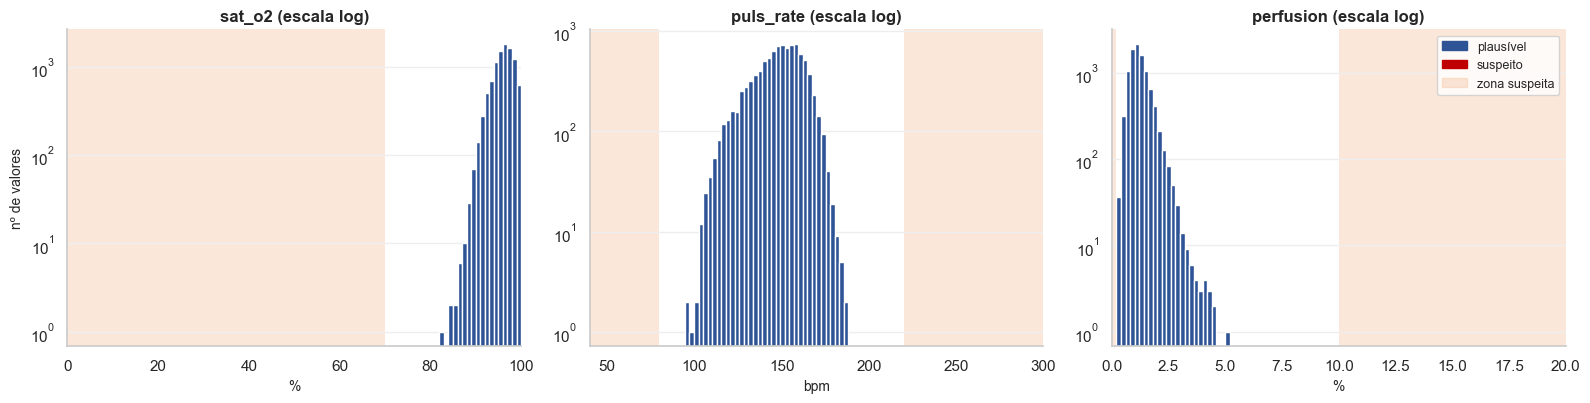

In [32]:
# =============================================================================
# 2.4.6b Sinais vitais: valores suspeitos (possíveis mas pouco realistas)
# Entre o impossível (2.4.6) e o normal há valores possíveis num momento de
# crise, mas muito improváveis como média de uma hora. Com base na literatura
# neonatal (ver relatório), um valor dentro do domínio é "suspeito" se:
#   saturação < 70 % | pulso < 80 ou > 220 bpm | perfusão < 0,2 % ou > 10 %
# Para cada valor suspeito vê-se o contexto, como faria um clínico:
#   - isolado: as horas vizinhas (1 h antes e 1 h depois, mesmo episódio)
#     não são suspeitas -> provável artefacto (ex.: sensor solto)
#   - sustentado: pelo menos uma hora vizinha também é suspeita no mesmo
#     sentido -> provável evento real
#   - sem vizinhos: não há hora anterior nem seguinte para comparar
# e se outro sinal vital também é suspeito na mesma hora.
# Vista temporária: código normalizado (2.4.3), datas válidas, horas 0–23,
# sem linhas repetidas e com os valores impossíveis (2.4.6) em falta.
# Os dados não são alterados.
# =============================================================================
PLAUSIVEL = {"sat_o2": (70, 100), "puls_rate": (80, 220), "perfusion": (0.2, 10)}

vista = pd.concat([pd.DataFrame({"episodio": df_sinais["episodio"].map(normalizar_codigo),
                                 "data": pd.to_datetime(df_sinais["data"], format="%Y-%m-%d", errors="coerce"),
                                 "hora": pd.to_numeric(df_sinais["hora"], errors="coerce")}),
                   num.where(cat != "fora do domínio")], axis=1)
vista = vista[vista["data"].notna() & vista["hora"].between(0, 23)].drop_duplicates()
vista["momento"] = vista["data"] + pd.to_timedelta(vista["hora"], unit="h")
vista = vista.sort_values(["episodio", "momento"]).reset_index(drop=True)

# sentido do valor: -1 abaixo do intervalo plausível, +1 acima, 0 plausível, NaN em falta
sentido = pd.DataFrame({v: np.select([vista[v] < PLAUSIVEL[v][0], vista[v] > PLAUSIVEL[v][1]], [-1, 1], 0)
                        for v in VITAIS}, index=vista.index).where(vista[VITAIS].notna())

mesmo_ep_ant = (vista["episodio"] == vista["episodio"].shift(1)) & \
               (vista["momento"] - vista["momento"].shift(1) == pd.Timedelta(hours=1))
mesmo_ep_seg = (vista["episodio"] == vista["episodio"].shift(-1)) & \
               (vista["momento"].shift(-1) - vista["momento"] == pd.Timedelta(hours=1))

resumo, detalhe = {}, []
for v in VITAIS:
    s = sentido[v]
    susp = s.isin([-1, 1])
    ant = s.shift(1).where(mesmo_ep_ant)        # sentido da hora anterior (NaN se não existir)
    seg = s.shift(-1).where(mesmo_ep_seg)       # sentido da hora seguinte
    tem_viz = ant.notna() | seg.notna()
    sustentado = (ant == s) | (seg == s)
    contexto = np.select([~tem_viz, sustentado], ["sem vizinhos", "sustentado"], "isolado")
    outro = sentido.drop(columns=v).isin([-1, 1]).any(axis=1)

    resumo[v] = {"dentro do domínio": vista[v].notna().sum(),
                 "suspeitos abaixo": (s == -1).sum(), "suspeitos acima": (s == 1).sum(),
                 "% suspeitos": round(susp.sum() / vista[v].notna().sum() * 100, 3),
                 "isolados": ((contexto == "isolado") & susp).sum(),
                 "sustentados": ((contexto == "sustentado") & susp).sum(),
                 "sem vizinhos": ((contexto == "sem vizinhos") & susp).sum(),
                 "com outro sinal suspeito na mesma hora": (outro & susp).sum()}
    for i in vista.index[susp]:
        detalhe.append({"sinal vital": v, "episódio": vista.at[i, "episodio"],
                        "momento": f"{vista.at[i, 'momento']:%d/%m %Hh}", "valor": vista.at[i, v],
                        "hora anterior": vista.at[i - 1, v] if mesmo_ep_ant[i] else np.nan,
                        "hora seguinte": vista.at[i + 1, v] if mesmo_ep_seg[i] else np.nan,
                        "contexto": contexto[i], "outro sinal suspeito": "sim" if outro[i] else "não"})

print(f"Intervalos de plausibilidade: {PLAUSIVEL}")
display(pd.DataFrame.from_dict(resumo, orient="index"))
if detalhe:
    tab_susp = pd.DataFrame(detalhe)
    print(f"Valores suspeitos: {len(tab_susp)} (mostram-se os sustentados e os sem vizinhos primeiro, até 40)")
    ordem_ctx = {"sustentado": 0, "sem vizinhos": 1, "isolado": 2}
    display(tab_susp.sort_values("contexto", key=lambda c: c.map(ordem_ctx)).head(40).reset_index(drop=True))

# --- Gráfico: distribuição de cada sinal vital (dentro do domínio) com as zonas suspeitas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, v in zip(axes, VITAIS):
    lo, hi = DOMINIO[v]
    p_lo, p_hi = PLAUSIVEL[v]
    bins = np.linspace(lo, hi, 101)
    valores = vista[v].dropna()
    ax.hist(valores[sentido.loc[valores.index, v] == 0], bins=bins, color=AZUL, zorder=2)
    ax.hist(valores[sentido.loc[valores.index, v].isin([-1, 1])], bins=bins, color=VERMELHO, zorder=2)
    ax.set_yscale("log")
    ax.axvspan(lo, p_lo, color=LARANJA, alpha=0.3, lw=0, zorder=0)
    if p_hi < hi:
        ax.axvspan(p_hi, hi, color=LARANJA, alpha=0.3, lw=0, zorder=0)
    ax.set_xlim(lo, hi)
    ax.set_title(f"{v} (escala log)")
    ax.set_xlabel(unidades[v])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("nº de valores")
axes[2].legend(handles=[Patch(color=AZUL, label="plausível"), Patch(color=VERMELHO, label="suspeito"),
                        Patch(color=LARANJA, alpha=0.3, label="zona suspeita")], loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

,valor original,nº de registos,nome oficial,tipo de erro
0,'ANEMIA',2,Anemia,maiúsculas/minúsculas
1,'Anemia ',1,Anemia,espaços a mais
2,'anemia',1,Anemia,maiúsculas/minúsculas
3,'CMV',2,Citomegalovírus,abreviatura
4,'Displasia Broncopulmonar',3,Displasia broncopulmonar,maiúsculas/minúsculas
5,'Doenca das membranas hialinas',9,Doença das membranas hialinas,acentos
6,'doença das membranas hialinas ',7,Doença das membranas hialinas,maiúsculas/minúsculas e espaços a mais
7,'DMH',6,Doença das membranas hialinas,abreviatura
8,'Ictericia neonatal',5,Icterícia neonatal,acentos
9,'ICTERÍCIA NEONATAL',3,Icterícia neonatal,maiúsculas/minúsculas


Nº de registos por tipo de erro:


tipo de erro,acentos,abreviatura,maiúsculas/minúsculas,maiúsculas/minúsculas e espaços a mais,espaços a mais,nome incompleto
nº de registos,16,9,9,7,2,2


,nome oficial exato,variantes,total depois de agrupar,% que vem de variantes
patologia,,,,
Doença das membranas hialinas,264,22,286,7.7
Icterícia neonatal,159,10,169,5.9
Anemia,52,4,56,7.1
Citomegalovírus,49,2,51,3.9
Displasia broncopulmonar,35,3,38,7.9
Persistência do canal arterial,31,1,32,3.1
Refluxo gastroesofágico,26,2,28,7.1
Sépsis,18,1,19,5.3
Lesão renal aguda,3,0,3,0.0


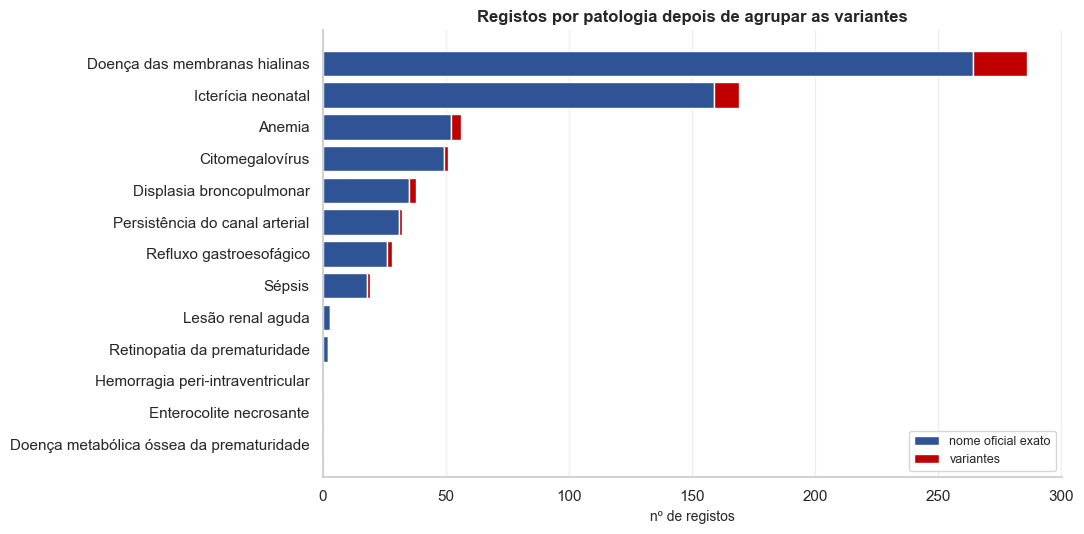

Variantes (com data válida) que repetem uma patologia já registada nesse episódio-dia: 0 de 44
Episódio-dia com 2 ou mais patologias – só nomes oficiais exatos: 155 de 425 (36.5%)
Episódio-dia com 2 ou mais patologias – depois de agrupar as variantes: 176 de 442 (39.8%)


In [33]:
# =============================================================================
# 2.4.7 Nomes de patologia fora da lista oficial
# Para cada valor de patologia que não é um dos 13 nomes oficiais, procura,
# numa cópia temporária, o nome oficial a que corresponde e o tipo de erro:
#   espaços a mais -> maiúsculas/minúsculas -> acentos -> abreviatura ->
#   nome incompleto -> gralha (nome muito parecido)
# Com esta normalização, só para medir, verifica-se:
# 1) que variantes existem, quantos registos têm e a que nome levam
# 2) quantos registos tem cada patologia antes e depois de agrupar
# 3) quantas variantes repetem uma patologia já registada nesse episódio-dia
#    (duplicados escondidos) e quanto muda a % de episódio-dia com várias
#    patologias (2.3.8)
# Usa normalizar_codigo (2.4.3) e, na parte 3, só datas válidas.
# Os dados não são alterados.
# =============================================================================
import unicodedata, difflib

def simples(texto):
    """minúsculas, sem acentos e com espaços simples (só para comparar)."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

ABREVIATURAS = {"dmh": "doenca das membranas hialinas", "cmv": "citomegalovirus",
                "pca": "persistencia do canal arterial", "rge": "refluxo gastroesofagico",
                "dbp": "displasia broncopulmonar", "rop": "retinopatia da prematuridade",
                "lra": "lesao renal aguda", "ecn": "enterocolite necrosante",
                "nec": "enterocolite necrosante", "hpiv": "hemorragia peri-intraventricular"}
OFICIAIS_SIMPLES = {simples(o): o for o in OFICIAIS}

def normalizar_patologia(valor):
    """Devolve (nome oficial ou None, tipo de erro)."""
    if pd.isna(valor):
        return None, "em falta"
    if valor in OFICIAIS:
        return valor, "nome oficial"
    v = str(valor)
    so_espacos = " ".join(v.split())
    s = simples(v)
    espacos = " e espaços a mais" if so_espacos != v else ""
    if so_espacos in OFICIAIS:
        return so_espacos, "espaços a mais"
    for o in OFICIAIS:
        if so_espacos.lower() == o.lower():
            return o, "maiúsculas/minúsculas" + espacos
    if s in OFICIAIS_SIMPLES:
        return OFICIAIS_SIMPLES[s], "acentos" + espacos
    abrev = ABREVIATURAS.get(s.replace(".", ""))
    if abrev in OFICIAIS_SIMPLES:
        return OFICIAIS_SIMPLES[abrev], "abreviatura"
    comecam = [o for k, o in OFICIAIS_SIMPLES.items() if k.startswith(s + " ")]
    if len(comecam) == 1:
        return comecam[0], "nome incompleto"
    parecido = difflib.get_close_matches(s, OFICIAIS_SIMPLES.keys(), n=1, cutoff=0.8)
    if parecido:
        return OFICIAIS_SIMPLES[parecido[0]], "gralha (nome parecido)"
    return None, "não reconhecido"

# --- 1) Variantes, nº de registos e nome oficial correspondente
variantes = df_patologias.loc[df_patologias["patologia"].notna() & ~df_patologias["patologia"].isin(OFICIAIS),
                              "patologia"].value_counts()
tab_var = pd.DataFrame([{"valor original": repr(v), "nº de registos": n,
                         "nome oficial": normalizar_patologia(v)[0], "tipo de erro": normalizar_patologia(v)[1]}
                        for v, n in variantes.items()])
display(tab_var.sort_values(["nome oficial", "nº de registos"], ascending=[True, False]).reset_index(drop=True))
print("Nº de registos por tipo de erro:")
display(tab_var.groupby("tipo de erro")["nº de registos"].sum().sort_values(ascending=False).to_frame().T)

# --- 2) Nº de registos por patologia: nome oficial exato vs. variantes
norm = df_patologias["patologia"].map(lambda v: normalizar_patologia(v)[0])
exato = df_patologias["patologia"].isin(OFICIAIS)
contagem = pd.DataFrame({"nome oficial exato": norm[exato].value_counts(),
                         "variantes": norm[~exato].value_counts()}).reindex(OFICIAIS).fillna(0).astype(int)
contagem["total depois de agrupar"] = contagem.sum(axis=1)
contagem["% que vem de variantes"] = (contagem["variantes"] / contagem["total depois de agrupar"] * 100).round(1)
contagem = contagem.sort_values("total depois de agrupar", ascending=False)
display(contagem)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(contagem.index, contagem["nome oficial exato"], color=AZUL, label="nome oficial exato")
ax.barh(contagem.index, contagem["variantes"], left=contagem["nome oficial exato"], color=VERMELHO, label="variantes")
ax.invert_yaxis()
ax.set_xlabel("nº de registos")
ax.set_title("Registos por patologia depois de agrupar as variantes")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# --- 3) Duplicados escondidos e efeito na % multi-label
datas_p = pd.to_datetime(df_patologias["data"], format="%Y-%m-%d", errors="coerce")
vista = pd.DataFrame({"episodio": df_patologias["episodio"].map(normalizar_codigo), "data": datas_p,
                      "patologia": norm, "exato": exato})[datas_p.notna() & norm.notna()]
antes = vista[vista["exato"]].drop_duplicates(["episodio", "data", "patologia"])
chaves_antes = set(zip(antes["episodio"], antes["data"], antes["patologia"]))
var = vista[~vista["exato"]]
repetem = [(e, d, p) in chaves_antes for e, d, p in zip(var["episodio"], var["data"], var["patologia"])]
print(f"Variantes (com data válida) que repetem uma patologia já registada nesse episódio-dia: "
      f"{sum(repetem)} de {len(var)}")

depois = vista.drop_duplicates(["episodio", "data", "patologia"])
for nome, t in [("só nomes oficiais exatos", antes), ("depois de agrupar as variantes", depois)]:
    n = t.groupby(["episodio", "data"])["patologia"].nunique()
    print(f"Episódio-dia com 2 ou mais patologias – {nome}: {(n >= 2).sum()} de {len(n)} ({(n >= 2).mean():.1%})")

### Relatório de Qualidade dos Dados

**Nota sobre os dados usados**

Todos os problemas foram medidos com os dados tal como foram fornecidos, **sem qualquer correção**. Para saber a que valor correto corresponde um valor errado (código de episódio, data, hora ou nome de patologia), a normalização foi feita apenas numa cópia temporária, usada para medir. As correções propostas neste relatório serão aplicadas na Fase 3 (Data Preparation).

**Resumo dos problemas encontrados**

| Problema | Tabela | Dimensão | Recuperável? | Correção proposta (Fase 3) |
|---|---|---|---|---|
| Valores em falta nos sinais vitais | Sinais vitais | 44 / 64 / 42 (0,4–0,7 %) | — | Preencher com as horas vizinhas do mesmo episódio ou ignorar na agregação diária |
| Linhas sem patologia | Patologias | 12 (1,7 %) | — | Descartar as 8 que têm outra patologia no mesmo dia; as 4 restantes dependem da resposta do professor |
| Linhas totalmente repetidas | Ambas | 60 (0,6 %) / 15 (2,2 %) | Sim | Manter a primeira ocorrência |
| Códigos de episódio fora do formato | Ambas | 12 / 6 registos | Sim (todos) | Retirar espaços e passar a maiúsculas |
| Datas no formato DD/MM/AAAA | Ambas | 15 / 8 registos | Sim | Reescrever como AAAA-MM-DD |
| Datas impossíveis (2024-13-02, 30 e 31 de fevereiro) | Ambas | 3 / 2 registos | Não | Descartar |
| Horas fora de 0–23 (−1, 24, 25) | Sinais vitais | 8 registos | Em 6 casos | Atribuir a única hora em falta nesse dia; descartar ou manter só no dia nos 2 dias parciais |
| Decimais com vírgula | Sinais vitais | 3 / 7 / 5 valores | Sim (todos) | Trocar a vírgula por ponto |
| Valores fora do domínio (impossíveis) | Sinais vitais | 27 / 20 / 23 valores | Não | Passar a valor em falta (só esse valor; o registo mantém-se) |
| Nomes de patologia fora da lista oficial | Patologias | 45 registos (6,5 %), 15 variantes | Sim (todos) | Substituir pelo nome oficial |

*Quando há três valores, referem-se a saturação / pulso / perfusão; quando há dois, a sinais vitais / patologias.*

Não foram encontrados valores suspeitos (possíveis mas clinicamente improváveis) nos sinais vitais (2.4.6b).

**Completude dos dados**

Os dados cobrem 82 dias (30/01/2024 a 20/04/2024) e 47 episódios, confirmados depois de normalizar os códigos. Todos os episódios têm sinais vitais e 39 têm patologias registadas; nenhum episódio aparece só na tabela de patologias. A cobertura tem, no entanto, limitações:
- 8 episódios não têm nenhuma patologia registada (EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047);
- 3 das 13 patologias oficiais não aparecem nos dados (hemorragia peri-intraventricular, enterocolite necrosante e doença metabólica óssea da prematuridade);
- 2 patologias são muito raras: lesão renal aguda (3 registos) e retinopatia da prematuridade (2);
- 13 episódios começam no primeiro ou terminam no último dia do período e podem estar incompletos;
- 3 episódios têm dias sem monitorização (EP004, EP006 e EP007, ver 2.4.4).

**Valores em falta (2.4.1)**

Nos sinais vitais faltam 44 valores de saturação (0,45 %), 64 de pulso (0,65 %) e 42 de perfusão (0,43 %). Não existem valores em falta escondidos (texto vazio ou só com espaços) em nenhuma variável. As falhas são quase sempre isoladas: 148 registos têm um só sinal vital em falta e apenas um registo tem dois (EP004, 07/02, 12h). São falhas pontuais e não horas inteiras perdidas.

Não há padrão nos valores em falta. 12 dos 47 episódios não têm nenhum. As percentagens mais altas (4,35 % no EP021 e no EP023) resultam sobretudo de haver poucos registos nesses episódios. Por hora, a percentagem varia entre 0,5 % e 2,7 % (2 a 11 registos), uma variação compatível com o acaso.

Na tabela de patologias há 12 linhas sem patologia (1,72 %). Em 8 delas, o mesmo episódio-dia tem outra patologia registada, pelo que são provavelmente linhas que sobraram. As outras 4 (EP002 a 04/02, EP019 a 28/02, EP025 a 20/03 e EP037 a 16/04) são o único registo desse dia, e não é possível saber se significam "sem patologia" ou "registo em falta".

**Registos duplicados (2.4.2)**

Existem 60 linhas repetidas nos sinais vitais (0,61 %), em 57 episódio-dia de 31 episódios, e 15 nas patologias (2,16 %), em 15 episódio-dia de 13 episódios. Todas as repetições são exatas: não há registos com a mesma chave e valores diferentes. Todas as cópias estão na linha imediatamente a seguir à original, o que indica que a mesma linha foi gravada duas vezes e não que um bloco de dados foi colado outra vez. A remoção das cópias não causa perda de informação.

**Códigos de episódio (2.4.3)**

Há 11 códigos fora do formato EPnnn nos sinais vitais (12 registos, 0,12 %) e 6 nas patologias (6 registos, 0,86 %). Os erros são de três tipos: minúsculas ('ep018'), espaço no início (' EP011') e espaço no meio ('EP 016'). Todos foram reconhecidos e correspondem a episódios que já existem. Nenhum destes registos repete um registo existente com o código certo: todos trazem informação nova, pelo que devem ser corrigidos e não eliminados.

**Datas inválidas (2.4.4)**

| Tipo de erro | Sinais vitais | Patologias | Situação depois de recuperar |
|---|---|---|---|
| Formato DD/MM/AAAA | 15 | 8 | Recuperável. Nos sinais vitais, todos preenchem uma hora em falta num dia que já tem registos; nas patologias, 6 caem num dia com registos e 2 num dia sem registos (EP023 a 12/03 e EP043 a 14/04) |
| "2024-13-02" | 2 | 1 | Não recuperável: trocar dia e mês dá 13/02, que fica fora do período dos episódios (EP018, EP042 e EP017) |
| Dia que não existe (31 e 30 de fevereiro) | 1 | 1 | Não recuperável |

Todas as datas no formato DD/MM/AAAA caem num dia que já existe no mesmo episódio, o que confirma a leitura dia/mês e não mês/dia.

Na exploração (2.3.3) colocou-se a hipótese de as falhas de dias no EP004, EP006 e EP007 resultarem de datas mal escritas (H4). **A hipótese foi rejeitada.** O EP004 e o EP007 não têm datas inválidas, e as duas datas inválidas do EP006 correspondem a 10/02, que não é nenhum dos dias em falta (06/02 a 08/02). Estas falhas são dias reais sem monitorização.

**Horas fora do domínio (2.4.5)**

Existem 8 registos com hora −1, 24 ou 25. Seis estão em dias com exatamente 23 horas válidas e não repetem os valores de nenhuma outra hora. Em nenhum destes seis a hora equivalente no dia ao lado (0h do dia seguinte ou 23h do dia anterior) está em falta. O registo pertence, portanto, ao próprio dia, e corresponde muito provavelmente à única hora em falta nesse dia.

Os outros dois registos (EP023 a 09/03 e EP031 a 29/03) estão em dias parciais, no início ou no fim do episódio. Nesses dias faltam muitas horas, pelo que não é possível saber qual era a hora correta. Como a análise vai ser feita por dia (H6), o impacto é mínimo.

**Valores de referência neonatais**

Para avaliar os sinais vitais, consultaram-se valores de referência neonatais na literatura:

| | Valores normais | Abaixo / acima do normal | Os nossos dados (mediana; P1–P99) |
|---|---|---|---|
| Saturação | Alvo de 90–95 % em prematuros que precisam de oxigénio [5]; não pode ultrapassar 100 % | < 90 % é dessaturação [5] | 96,3 %; 89,7–99,9 % |
| Pulso | Mediana de 127 bpm ao nascer, a subir até 145 bpm por volta de 1 mês [3]; normal de 100–160 bpm (NICE) [4] | Bradicardia clinicamente significativa < 80 bpm; a OMS considera anormal > 180 bpm [4] | 149 bpm; 111–175 bpm |
| Perfusão | Recém-nascidos saudáveis: mediana 1,70 %, IQR 1,18–2,50 %, P5 0,70 %, P95 4,50 % [1]; prematuros: mediana 0,9–1,3 % na 1.ª semana [2] | < 0,70 % pode indicar doença; < 0,50 % (P1) é hipoperfusão clara [1] | 1,15 %; 0,47–2,76 % |

Os dados são compatíveis com a literatura. A saturação está quase toda na faixa-alvo dos prematuros e o pulso dentro do intervalo normal neonatal. A perfusão mediana (1,15 %) está abaixo da dos recém-nascidos saudáveis e próxima da dos prematuros, o que sugere uma população sobretudo prematura. Isto é coerente com a patologia mais frequente, a doença das membranas hialinas, que é típica da prematuridade.

**Sinais vitais: valores não numéricos, impossíveis e outliers (2.4.6)**

Definiram-se limites de domínio que separam o fisicamente impossível do resto. Como não se sabe que aparelho registou os dados, os limites são fisiológicos e abrangentes:
- **saturação maior que 0 % e até 100 %:** a saturação é a percentagem da hemoglobina que transporta oxigénio, pelo que não pode ultrapassar 100 %; um valor de 0 % significa ausência de leitura;
- **pulso de 40 a 300 bpm:** fora deste intervalo não é compatível com um recém-nascido vivo;
- **perfusão maior que 0 % e até 20 %:** uma perfusão de 0 % significa ausência de sinal de pulso e 20 % é mais de quatro vezes o P95 dos recém-nascidos saudáveis.

As especificações de um oxímetro neonatal de uso corrente são compatíveis com estes limites: medem a saturação até 100 % e a perfusão entre 0,02 % e 20 % [6].

| | Saturação | Pulso | Perfusão |
|---|---|---|---|
| Em falta | 44 | 64 | 42 |
| Não numérico (decimal com vírgula) | 3 | 7 | 5 |
| Fora do domínio (impossível) | 27 | 20 | 23 |
| Outlier pela regra do IQR, mas plausível | 148 | 79 | 302 |
| **Inutilizáveis** (em falta + não numérico + impossível) | **0,75 %** | **0,92 %** | **0,71 %** |

Todos os valores não numéricos são decimais com vírgula e são recuperáveis. Os 70 valores impossíveis estão espalhados por 28 episódios e nunca há mais do que um no mesmo registo, por isso o resto do registo continua utilizável. São quase todos números redondos e repetidos, que parecem códigos de "sem leitura" ou erros de digitação:
- saturação: 999, 250, 150, −5 e −1;
- pulso: 999, 520, 400, 0 e −10;
- perfusão: 99, 50, 25, −1 e −0,5.

Há ainda 9 saturações entre 101 % e 104 %, todas números inteiros, que são impossíveis por definição.

A regra do IQR assinala 529 valores plausíveis como outliers, sobretudo na perfusão, cuja distribuição é assimétrica. Estes valores podem corresponder a bebés doentes e devem ser mantidos. O critério para identificar erros é, portanto, o domínio de cada variável e não a regra do IQR.

**Valores suspeitos (2.4.6b)**

Entre o impossível e o normal podem existir valores possíveis num momento de crise, mas muito improváveis como média de uma hora. Para os identificar, definiu-se um segundo nível, de plausibilidade clínica. Um valor dentro do domínio é considerado suspeito se:
- a saturação for inferior a 70 % (muito abaixo do alvo de 90 % [5] e abaixo do intervalo em que os oxímetros garantem exatidão [6]);
- o pulso for inferior a 80 bpm (bradicardia clinicamente significativa [4]) ou superior a 220 bpm;
- a perfusão for inferior a 0,2 % ou superior a 10 % (bem abaixo do P1 e mais do dobro do P95 dos recém-nascidos saudáveis [1]).

Os valores suspeitos seriam avaliados pelo contexto temporal:
- **isolados:** as horas vizinhas do mesmo episódio são normais, pelo que seriam provavelmente artefactos e passariam a valor em falta;
- **sustentados:** pelo menos uma hora vizinha também é suspeita no mesmo sentido, pelo que seriam provavelmente eventos reais e seriam mantidos.

**Não foi encontrado nenhum valor suspeito.** Todos os valores possíveis dos três sinais vitais (9 697 de saturação, 9 680 de pulso e 9 701 de perfusão) estão dentro dos intervalos de plausibilidade clínica, e a maioria está longe dos seus limites. A saturação mínima ronda os 82 %, o pulso varia entre cerca de 96 e 188 bpm e a perfusão entre cerca de 0,2 % e 5 %, valores compatíveis com a literatura neonatal. Os valores impossíveis estão muito afastados de todos os restantes, pelo que a regra do domínio é suficiente para separar os erros das medições reais, sem casos duvidosos.

**Nomes de patologia (2.4.7)**

Existem 15 variantes de nomes, em 45 registos (6,5 %), e todas correspondem a um nome oficial:

| Tipo de erro | Registos |
|---|---|
| Acentos (ex.: "Doenca das membranas hialinas", "Sepsis") | 16 |
| Abreviaturas (DMH, CMV, RGE) | 9 |
| Maiúsculas/minúsculas (ex.: "ANEMIA") | 9 |
| Maiúsculas/minúsculas e espaços a mais | 7 |
| Espaços a mais | 2 |
| Nome incompleto ("icterícia") | 2 |

As variantes representam entre 3 % e 8 % dos registos de cada patologia, pelo que a distribuição e a ordem das patologias quase não mudam depois de agrupar. Nenhuma variante repete uma patologia já registada no mesmo episódio-dia (0 de 44), por isso agrupar os nomes não cria duplicados. A percentagem de episódio-dia com duas ou mais patologias sobe de 36,5 % para **39,8 %** (176 de 442), o que confirma que o valor da 2.3.8 era um limite inferior.

**Episódios com o mesmo período (H5)**

Os pares de episódios com exatamente o mesmo período (EP015/EP016, EP017/EP018, EP039/EP040 e EP044/EP045) correspondem a bebés diferentes e não a registos duplicados. Os dois episódios de cada par têm níveis de sinais vitais diferentes (2.3.6; por exemplo, pulso mediano de cerca de 147 bpm no EP044 e de 162 bpm no EP045) e patologias diferentes (2.3.7; o EP044 não tem nenhuma e o EP045 tem doença das membranas hialinas e icterícia neonatal). São provavelmente gémeos e devem ser mantidos como episódios distintos.

**Atualização das hipóteses**

| # | Hipótese | Resultado da verificação |
|---|---|---|
| H1 | Os duplicados são exatos e não contraditórios | Confirmada: 0 contradições; todas as cópias estão logo a seguir à original |
| H2 | Várias patologias podem coexistir no mesmo dia | Confirmada: 39,8 % dos episódio-dia depois de agrupar os nomes |
| H4 | As falhas de dias resultam de datas mal escritas | Rejeitada: são dias reais sem monitorização |
| H5 | Os pares com o mesmo período são duplicados | Rejeitada: são bebés diferentes (provavelmente gémeos) |

**Questões a confirmar com o professor**

1. Concorda com os limites de domínio definidos (saturação > 0 e ≤ 100 %, pulso 40–300 bpm, perfusão > 0 e ≤ 20 %)?
2. Os valores 999, 99 e os valores negativos são códigos de "sem leitura"? Podem ser tratados como valores em falta?
3. Um dia sem patologia registada significa "sem patologia" ou "sem registo"? Isto aplica-se aos 8 episódios sem patologias e às 4 linhas sem patologia que são o único registo do dia.

**Conclusão**

A qualidade dos dados é boa e quase todos os problemas encontrados são recuperáveis. Os registos que se perdem são os 3 de sinais vitais e os 2 de patologias com data impossível, e eventualmente os 2 de sinais vitais com hora inválida em dias parciais. Os valores perdidos são os 70 valores de sinais vitais fora do domínio. Em todos os casos é menos de 1 % dos dados. Todos os valores possíveis dos sinais vitais são clinicamente plausíveis e compatíveis com a literatura neonatal.

A Fase 3 deverá aplicar as correções do quadro-resumo pela ordem seguinte:
1. normalizar os códigos, as datas e as horas;
2. remover os duplicados;
3. converter os decimais e passar os valores impossíveis a valor em falta;
4. agrupar os nomes das patologias.

Só depois de corrigidas é que as duas tabelas são integradas.

**Referências**

[1] Granelli, A. & Östman-Smith, I. (2007). Noninvasive peripheral perfusion index as a possible tool for screening for critical left heart obstruction. *Acta Paediatrica*, 96(10), 1455–1459.
[2] Perfusion index variations in clinically and hemodynamically stable preterm newborns in the first week of life. *Italian Journal of Pediatrics*, 36, 6 (2010).
[3] Fleming, S. et al. (2011). Normal ranges of heart rate and respiratory rate in children from birth to 18 years of age. *The Lancet*, 377(9770), 1011–1018.
[4] Heart rate in neonates: normal ranges and bradycardia. *Infant Journal*, 12(7).
[5] Johns Hopkins All Children's Hospital (2023). *Oxygen saturation targets for preterm infants* (clinical pathway).
[6] Masimo Corporation. *Rad-5 / Rad-8 Pulse Oximeter – Technical Specifications*.